# GLD et SLV — analyse et prévision des séries temporelles

**Période :** 2010–2025 · **Fréquence :** séances boursières · **Test :** derniers 10 %.

Exécuter les cellules dans l’ordre. Le dossier du projet contient `data/raw`, `data/processed`, `figures`, `models` et `reports/llm`. Placer le notebook à la racine ou dans `notebooks`.

**Dépendances :** numpy, pandas, matplotlib, seaborn, yfinance, statsmodels, pmdarima, arch, tensorflow, scikit-learn, scipy et joblib. Les annexes LLM doivent accompagner le projet.

Les sorties conservées proviennent des exécutions originales ; le nettoyage ne constitue pas une nouvelle estimation des modèles.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import statsmodels.api as sm

# Fixer la graine pour rendre les étapes aléatoires reproductibles.
np.random.seed(42)

# Harmoniser la présentation des graphiques.
sns.set_theme(style="whitegrid")

print("Python utilisé :", sys.executable)
print("Environnement prêt.")


Python utilisé : c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\Scripts\python.exe
Environnement prêt.


In [2]:
from pathlib import Path

# Trouver la racine du projet depuis le dossier courant du notebook.
dossier_courant = Path.cwd().resolve()
candidats = [dossier_courant, *dossier_courant.parents]

racine = next(
    (p for p in candidats if p.name == "projet_or_argent"),
    None
)

if racine is None:
    racine = dossier_courant.parent if dossier_courant.name == "notebooks" else dossier_courant


print("Racine du projet :", racine)


Racine du projet : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent


## 1. Collecte des données

Nous récupérons les historiques quotidiens de GLD et SLV
du 1er janvier 2010 au 31 décembre 2025.

Nous conservons les prix bruts, les prix de clôture ajustés
et les volumes pour documenter les données utilisées.


In [3]:
# Télécharger séparément les actifs pour obtenir des tableaux simples.
donnees_brutes = {}

for symbole in ["GLD", "SLV"]:
    df = yf.download(
        symbole,
        start="2010-01-01",
        end="2026-01-01",
        interval="1d",
        auto_adjust=False,
        multi_level_index=False,
        keepna=True,
        threads=False,
        timeout=30,
        progress=False
    )

    # Arrêter si le téléchargement n'a pas fourni de prix exploitables.
    if df is None or df.empty:
        raise RuntimeError(f"Échec du téléchargement pour {symbole}.")

    if "Adj Close" not in df.columns or df["Adj Close"].dropna().empty:
        raise RuntimeError(f"Prix ajustés absents pour {symbole}.")

    donnees_brutes[symbole] = df.sort_index()

    print(
        f"{symbole} : {len(df)} lignes | "
        f"{df.index.min().date()} → {df.index.max().date()}"
    )

display(donnees_brutes["GLD"].head())
display(donnees_brutes["SLV"].head())


GLD : 4024 lignes | 2010-01-04 → 2025-12-31
SLV : 4024 lignes | 2010-01-04 → 2025-12-31


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2010-01-04,109.800003,109.800003,110.139999,109.309998,109.820000,16224100
2010-01-05,109.699997,109.699997,110.389999,109.260002,109.879997,14213100
2010-01-06,111.510002,111.510002,111.769997,110.410004,110.709999,24981900
2010-01-07,110.820000,110.820000,111.290001,110.620003,111.070000,13609800
2010-01-08,111.370003,111.370003,111.580002,110.260002,111.519997,15894600


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2010-01-04,17.230000,17.230000,17.250000,17.020000,17.049999,9720500
2010-01-05,17.510000,17.510000,17.549999,17.180000,17.240000,13318600
2010-01-06,17.860001,17.860001,17.900000,17.629999,17.660000,14047000
2010-01-07,17.889999,17.889999,18.020000,17.799999,17.860001,12587200
2010-01-08,18.150000,18.150000,18.160000,17.930000,18.139999,11736100


In [4]:
# Vérifier la qualité avant toute suppression ou transformation.
for symbole, df in donnees_brutes.items():
    print(f"\n--- {symbole} ---")
    print("Nombre de lignes :", len(df))
    print("Première date :", df.index.min().date())
    print("Dernière date :", df.index.max().date())
    print("Dates dupliquées :", df.index.duplicated().sum())
    print("Dates triées :", df.index.is_monotonic_increasing)

    print("\nValeurs manquantes par colonne :")
    print(df.isna().sum())

    print("\nPrix ajustés nuls ou négatifs :",
          (df["Adj Close"] <= 0).sum())



--- GLD ---
Nombre de lignes : 4024
Première date : 2010-01-04
Dernière date : 2025-12-31
Dates dupliquées : 0
Dates triées : True

Valeurs manquantes par colonne :
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Prix ajustés nuls ou négatifs : 0

--- SLV ---
Nombre de lignes : 4024
Première date : 2010-01-04
Dernière date : 2025-12-31
Dates dupliquées : 0
Dates triées : True

Valeurs manquantes par colonne :
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Prix ajustés nuls ou négatifs : 0


In [5]:
# Conserver les données brutes pour reproduire l'analyse sans téléchargement.
dossier_brut = racine / "data" / "raw"
dossier_brut.mkdir(parents=True, exist_ok=True)

for symbole, df in donnees_brutes.items():
    fichier = dossier_brut / f"{symbole}_2010_2025.csv"
    df.to_csv(fichier, index_label="Date", date_format="%Y-%m-%d")
    print("Fichier sauvegardé :", fichier)

Fichier sauvegardé : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\data\raw\GLD_2010_2025.csv
Fichier sauvegardé : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\data\raw\SLV_2010_2025.csv


## 2. Préparation du tableau commun et séparation temporelle

Nous alignons les prix ajustés de GLD et SLV par date.
Les premiers 90 % des observations servent à l’apprentissage ;
les derniers 10 % sont réservés au test.


In [6]:
# Vérifier l'alignement avant de comparer les deux actifs.
assert donnees_brutes["GLD"].index.equals(
    donnees_brutes["SLV"].index
), "Les dates des deux historiques diffèrent."

prix = pd.concat(
    [
        donnees_brutes["GLD"]["Adj Close"].rename("GLD"),
        donnees_brutes["SLV"]["Adj Close"].rename("SLV")
    ],
    axis=1
).sort_index()

prix.index.name = "Date"

assert not prix.isna().any().any(), "Des prix sont manquants."

print("Dimensions du tableau :", prix.shape)
display(prix.head())


Dimensions du tableau : (4024, 2)


,GLD,SLV
Date,,
2010-01-04,109.800003,17.230000
2010-01-05,109.699997,17.510000
2010-01-06,111.510002,17.860001
2010-01-07,110.820000,17.889999
2010-01-08,111.370003,18.150000


In [7]:
# Réserver la fin de l'historique pour évaluer les prévisions.
n_train = int(len(prix) * 0.90)

prix_train = prix.iloc[:n_train].copy()
prix_test = prix.iloc[n_train:].copy()

for nom, tableau in [
    ("Apprentissage", prix_train),
    ("Test", prix_test)
]:
    print(
        f"{nom} : {len(tableau)} séances | "
        f"{tableau.index.min().date()} → "
        f"{tableau.index.max().date()}"
    )


Apprentissage : 3621 séances | 2010-01-04 → 2024-05-22
Test : 403 séances | 2024-05-23 → 2025-12-31


In [8]:
# Conserver exactement les mêmes données et dates pour les deux langages.
dossier_prepare = racine / "data" / "processed"
dossier_prepare.mkdir(parents=True, exist_ok=True)

for nom, tableau in {
    "prix_or_argent.csv": prix,
    "prix_train.csv": prix_train,
    "prix_test.csv": prix_test
}.items():
    tableau.to_csv(
        dossier_prepare / nom,
        index_label="Date",
        date_format="%Y-%m-%d"
    )

print("Sauvegarde terminée :", dossier_prepare)


Sauvegarde terminée : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\data\processed


## 3. Analyse exploratoire — évolution des prix

Nous visualisons les prix ajustés sur la période d’apprentissage.
Nous comparons ensuite leurs évolutions en base 100 pour neutraliser
la différence de niveau entre les prix des deux instruments.


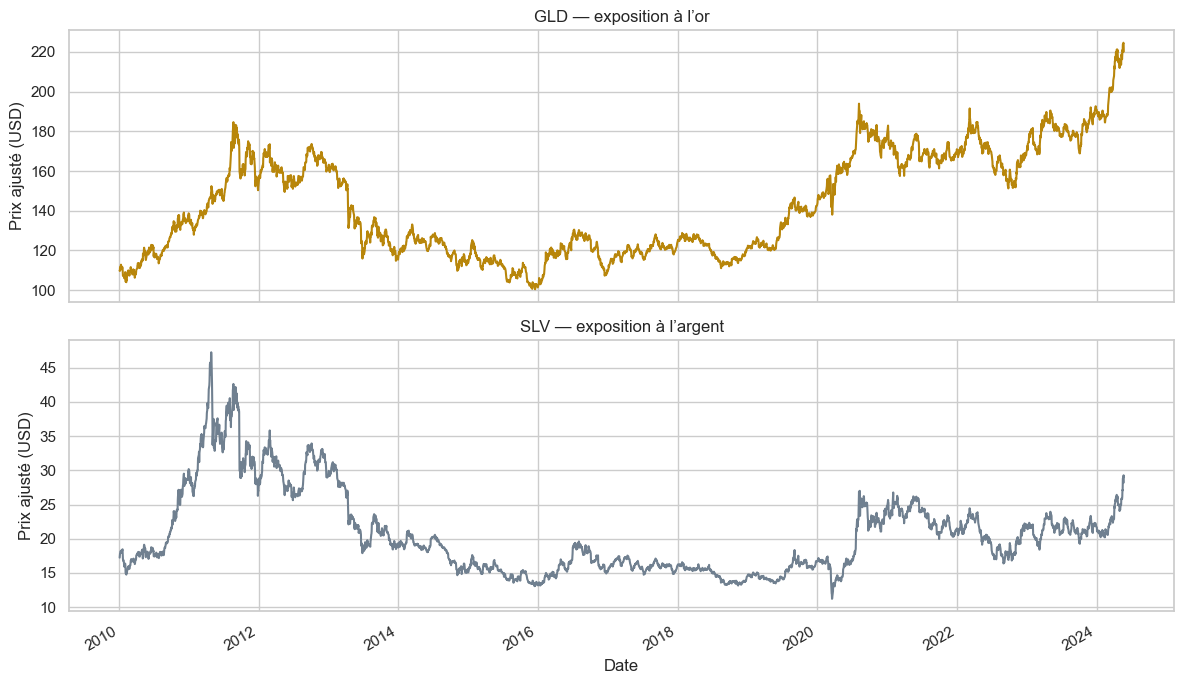

In [9]:
# Séparer les axes pour rendre chaque évolution lisible.
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

prix_train["GLD"].plot(
    ax=axes[0], color="darkgoldenrod", title="GLD — exposition à l’or"
)
axes[0].set_ylabel("Prix ajusté (USD)")

prix_train["SLV"].plot(
    ax=axes[1], color="slategray", title="SLV — exposition à l’argent"
)
axes[1].set_ylabel("Prix ajusté (USD)")
axes[1].set_xlabel("Date")

plt.tight_layout()

dossier_figures = racine / "figures"
dossier_figures.mkdir(parents=True, exist_ok=True)
fig.savefig(
    dossier_figures / "01_prix_apprentissage.png",
    dpi=150, bbox_inches="tight"
)

plt.show()


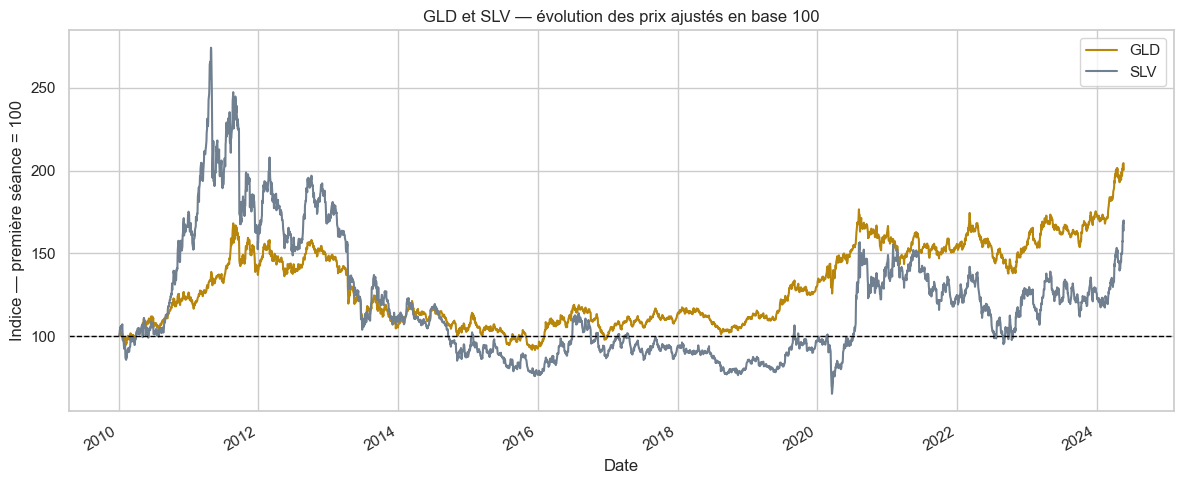

In [10]:
# Donner le même point de départ pour comparer les variations relatives.
prix_base100 = prix_train.div(prix_train.iloc[0]).mul(100)

ax = prix_base100.plot(
    figsize=(12, 5),
    color=["darkgoldenrod", "slategray"],
    title="GLD et SLV — évolution des prix ajustés en base 100"
)

ax.set_ylabel("Indice — première séance = 100")
ax.set_xlabel("Date")
ax.axhline(100, color="black", linestyle="--", linewidth=1)

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(
    dossier_figures / "02_prix_base100_apprentissage.png",
    dpi=150, bbox_inches="tight"
)

plt.show()


In [11]:
# Mesurer les variations relatives sur la période d’apprentissage.
rendements_train = 100 * np.log(prix_train).diff().dropna()

print("Nombre de rendements :", len(rendements_train))
display(rendements_train.head())


Nombre de rendements : 3620


,GLD,SLV
Date,,
2010-01-05,-0.091122,1.612014
2010-01-06,1.636495,1.979145
2010-01-07,-0.620703,0.167825
2010-01-08,0.495076,1.442868
2010-01-11,1.320147,0.330030


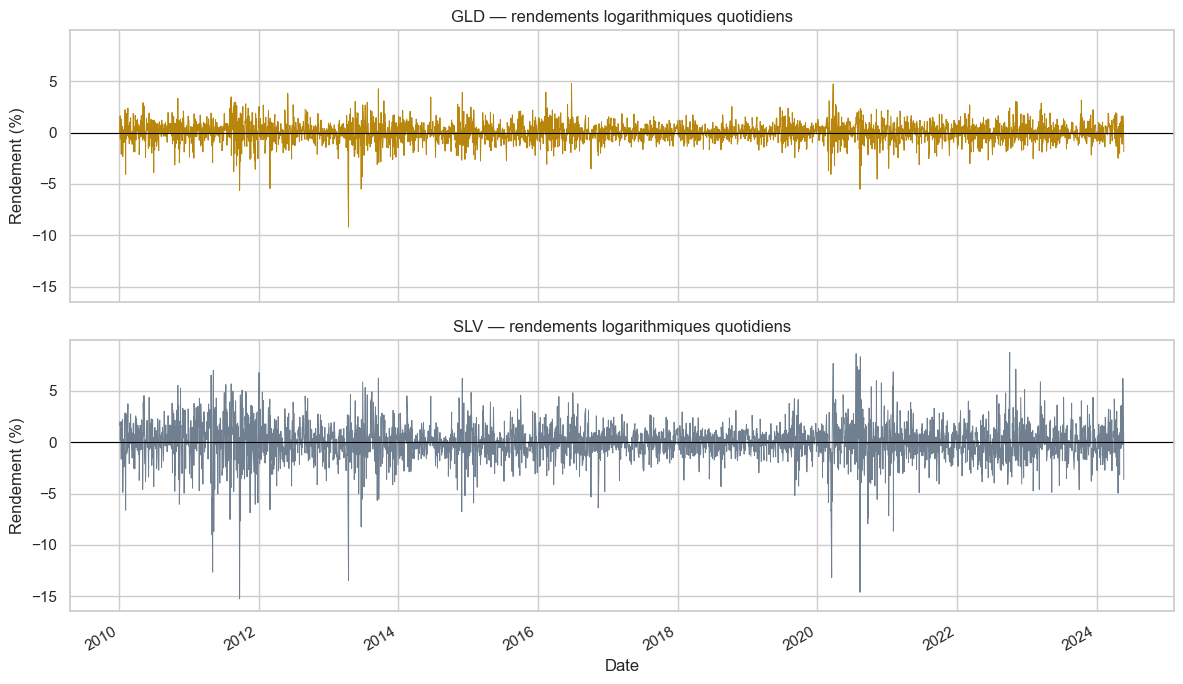

In [12]:
# Garder la même échelle pour comparer l’amplitude des fluctuations.
fig, axes = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, sharey=True
)

for ax, symbole, couleur in zip(
    axes, ["GLD", "SLV"], ["darkgoldenrod", "slategray"]
):
    rendements_train[symbole].plot(ax=ax, color=couleur, linewidth=0.7)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{symbole} — rendements logarithmiques quotidiens")
    ax.set_ylabel("Rendement (%)")

axes[1].set_xlabel("Date")
fig.tight_layout()
fig.savefig(
    dossier_figures / "03_rendements_apprentissage.png",
    dpi=150, bbox_inches="tight"
)
plt.show()


In [13]:
# Résumer le niveau, la dispersion et la forme des rendements.
statistiques = pd.DataFrame({
    "Moyenne (%)": rendements_train.mean(),
    "Écart-type (%)": rendements_train.std(),
    "Variance": rendements_train.var(),
    "Minimum (%)": rendements_train.min(),
    "Maximum (%)": rendements_train.max(),
    "Asymétrie": rendements_train.skew(),
    "Excès de kurtosis": rendements_train.kurt()
})

display(statistiques.round(4))

print("\nCorrélation entre les rendements :")
display(rendements_train.corr().round(4))

statistiques.to_csv(dossier_prepare / "statistiques_rendements_train.csv")
rendements_train.to_csv(
    dossier_prepare / "rendements_train.csv",
    index_label="Date",
    date_format="%Y-%m-%d"
)


,Moyenne (%),Écart-type (%),Variance,Minimum (%),Maximum (%),Asymétrie,Excès de kurtosis
GLD,0.0192,0.9773,0.9550,-9.1905,4.7874,-0.5015,4.9959
SLV,0.0136,1.8208,3.3154,-15.2529,8.7487,-0.7166,7.0799



Corrélation entre les rendements :


,GLD,SLV
GLD,1.0000,0.7907
SLV,0.7907,1.0000


### Interprétation des rendements

Sur la période d’apprentissage, SLV présente une volatilité quotidienne
plus élevée que GLD : les écarts-types des rendements logarithmiques
sont respectivement de 1,8208 % et 0,9773 %.

Les deux distributions ont une asymétrie négative et un excès de
kurtosis positif, indiquant des queues plus lourdes que celles
d’une distribution normale.

La corrélation des rendements est de 0,7907 : les deux actifs évoluent
souvent dans le même sens. Cette association ne démontre toutefois
ni une causalité ni une relation d’équilibre à long terme.


## 4. Tests de stationnarité : ADF et KPSS

Les tests sont réalisés uniquement sur l’apprentissage :
- sur les logarithmes des prix ;
- sur leurs premières différences, les rendements logarithmiques.

Nous examinons les prix avec et sans tendance déterministe
pour vérifier la sensibilité des conclusions.


In [14]:
from statsmodels.tsa.stattools import adfuller, kpss

log_prix_train = np.log(prix_train)
resultats = []

for symbole in ["GLD", "SLV"]:
    # Tester les niveaux avec constante, puis constante et tendance.
    # Tester les rendements avec constante, sans tendance imposée.
    configurations = [
        ("Log-prix", log_prix_train[symbole], "c"),
        ("Log-prix", log_prix_train[symbole], "ct"),
        ("Rendement", rendements_train[symbole], "c")
    ]

    for transformation, serie, regression in configurations:
        serie = serie.dropna()

        adf = adfuller(
            serie, regression=regression, autolag="AIC"
        )
        resultat_kpss = kpss(
            serie, regression=regression, nlags="auto"
        )

        resultats.append({
            "Actif": symbole,
            "Série": transformation,
            "Spécification": regression,
            "ADF statistique": adf[0],
            "ADF p-value": adf[1],
            "ADF retards": adf[2],
            "KPSS statistique": resultat_kpss[0],
            "KPSS p-value": resultat_kpss[1],
            "KPSS retards": resultat_kpss[2]
        })

tests_stationnarite = pd.DataFrame(resultats)

display(tests_stationnarite.round(4))

tests_stationnarite.to_csv(
    dossier_prepare / "tests_stationnarite_train.csv",
    index=False
)


C:\Users\nourc\AppData\Local\Temp\ipykernel_1364\2357731380.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(
C:\Users\nourc\AppData\Local\Temp\ipykernel_1364\2357731380.py:21: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  resultat_kpss = kpss(
C:\Users\nourc\AppData\Local\Temp\ipykernel_1364\2357731380.py:21: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior 

,Actif,Série,Spécification,ADF statistique,ADF p-value,ADF retards,KPSS statistique,KPSS p-value,KPSS retards
0,GLD,Log-prix,c,-0.9691,0.7644,0,3.4389,0.01,38
1,GLD,Log-prix,ct,-1.4633,0.8414,0,1.5355,0.01,38
2,GLD,Rendement,c,-60.6076,0.0000,0,0.1381,0.10,5
3,SLV,Log-prix,c,-1.8496,0.3561,0,1.9700,0.01,38
4,SLV,Log-prix,ct,-1.8237,0.6932,0,1.3087,0.01,38
5,SLV,Rendement,c,-59.0322,0.0000,0,0.1009,0.10,2


### Conclusion des tests de stationnarité

Pour GLD et SLV, ADF ne rejette pas la présence d’une racine unitaire
dans les log-prix, tandis que KPSS rejette leur stationnarité.
Cette conclusion reste identique avec une constante et une tendance.

Après une première différenciation des log-prix, ADF rejette la
racine unitaire et KPSS ne rejette pas la stationnarité des rendements.

Les résultats soutiennent donc un ordre d’intégration I(1) des
log-prix et le choix d = 1 pour leur modélisation ARIMA.
Ils ne permettent pas de conclure à l’absence de volatilité conditionnelle.


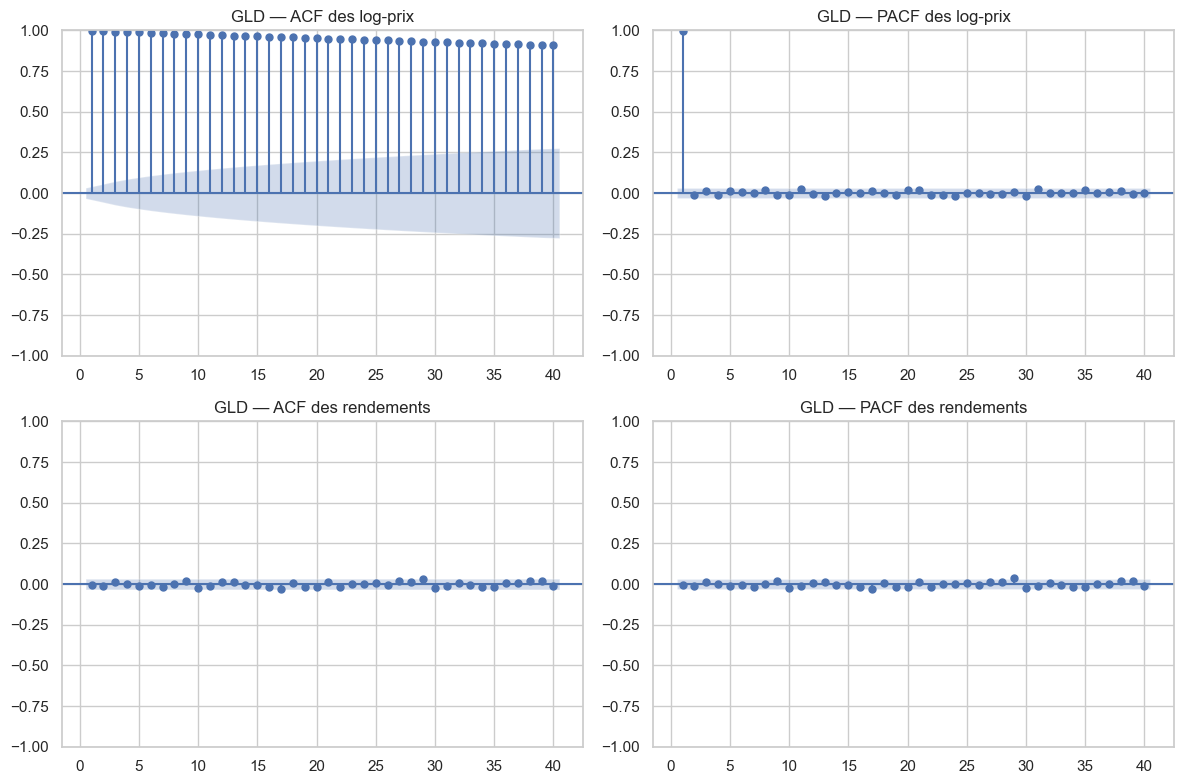

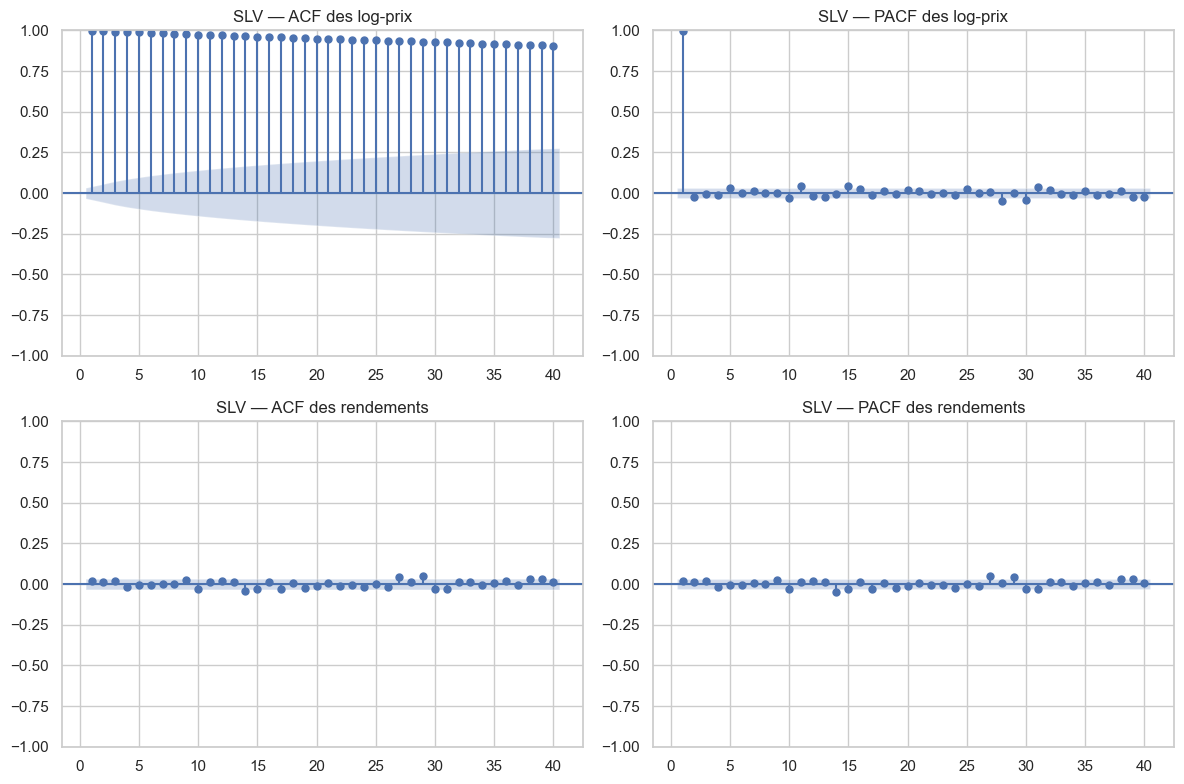

In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Comparer la dépendance temporelle avant et après différenciation.
for symbole in ["GLD", "SLV"]:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    plot_acf(
        log_prix_train[symbole], lags=40, zero=False,
        ax=axes[0, 0]
    )
    axes[0, 0].set_title(f"{symbole} — ACF des log-prix")

    plot_pacf(
        log_prix_train[symbole], lags=40, zero=False,
        method="ywm", ax=axes[0, 1]
    )
    axes[0, 1].set_title(f"{symbole} — PACF des log-prix")

    plot_acf(
        rendements_train[symbole], lags=40, zero=False,
        ax=axes[1, 0]
    )
    axes[1, 0].set_title(f"{symbole} — ACF des rendements")

    plot_pacf(
        rendements_train[symbole], lags=40, zero=False,
        method="ywm", ax=axes[1, 1]
    )
    axes[1, 1].set_title(f"{symbole} — PACF des rendements")

    fig.tight_layout()
    fig.savefig(
        dossier_figures / f"04_acf_pacf_{symbole}.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()


In [16]:
from statsmodels.tsa.stattools import acf, pacf

# Examiner les premiers retards pour proposer de petits modèles candidats.
for symbole in ["GLD", "SLV"]:
    serie = rendements_train[symbole]

    valeurs_acf, intervalles_acf = acf(
        serie, nlags=10, alpha=0.05, fft=True
    )
    valeurs_pacf, intervalles_pacf = pacf(
        serie, nlags=10, alpha=0.05, method="ywm"
    )

    tableau = pd.DataFrame({
        "Retard": range(1, 11),
        "ACF": valeurs_acf[1:],
        "ACF IC inférieur": intervalles_acf[1:, 0],
        "ACF IC supérieur": intervalles_acf[1:, 1],
        "PACF": valeurs_pacf[1:],
        "PACF IC inférieur": intervalles_pacf[1:, 0],
        "PACF IC supérieur": intervalles_pacf[1:, 1]
    })

    print(f"\n--- {symbole} ---")
    print(tableau.round(4).to_string(index=False))



--- GLD ---
 Retard     ACF  ACF IC inférieur  ACF IC supérieur    PACF  PACF IC inférieur  PACF IC supérieur
      1 -0.0082           -0.0408            0.0244 -0.0082            -0.0408             0.0244
      2 -0.0133           -0.0459            0.0193 -0.0134            -0.0459             0.0192
      3  0.0153           -0.0173            0.0479  0.0151            -0.0175             0.0476
      4 -0.0024           -0.0349            0.0302 -0.0023            -0.0349             0.0303
      5 -0.0144           -0.0469            0.0182 -0.0140            -0.0466             0.0186
      6 -0.0037           -0.0363            0.0289 -0.0042            -0.0368             0.0284
      7 -0.0152           -0.0478            0.0174 -0.0156            -0.0482             0.0170
      8  0.0020           -0.0307            0.0346  0.0020            -0.0306             0.0346
      9  0.0212           -0.0114            0.0538  0.0209            -0.0117             0.0534
     10

C:\Users\nourc\AppData\Local\Temp\ipykernel_1364\1981134676.py:7: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  valeurs_acf, intervalles_acf = acf(
C:\Users\nourc\AppData\Local\Temp\ipykernel_1364\1981134676.py:7: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  valeurs_acf, intervalles_acf = acf(


### Interprétation de l’ACF et de la PACF des rendements

Pour GLD, aucun des dix premiers retards ne présente une
autocorrélation significative au seuil nominal de 5 %.

Pour SLV, la PACF au retard 10 est légèrement significative,
mais ce signal isolé doit être interprété avec prudence,
car plusieurs retards sont examinés.

Nous retenons donc ARIMA(0,1,0) comme premier candidat sur
les log-prix, avec et sans dérive. Des modèles de faible ordre
seront comparés pour vérifier l’intérêt de termes AR ou MA.

Ces observations ne permettent pas de conclure à l’indépendance
des rendements ni à l’absence d’effets de volatilité conditionnelle.


In [17]:
# Repérer les rendements extrêmes avec la règle descriptive de l'IQR.
q1 = rendements_train.quantile(0.25)
q3 = rendements_train.quantile(0.75)
iqr = q3 - q1

borne_basse = q1 - 1.5 * iqr
borne_haute = q3 + 1.5 * iqr

masque_extremes = (
    rendements_train.lt(borne_basse)
    | rendements_train.gt(borne_haute)
)

resume_extremes = pd.DataFrame({
    "Borne basse (%)": borne_basse,
    "Borne haute (%)": borne_haute,
    "Nombre signalé": masque_extremes.sum(),
    "Part signalée (%)": 100 * masque_extremes.mean()
})

display(resume_extremes.round(4))

# Afficher les cinq mouvements les plus forts de chaque actif.
for symbole in ["GLD", "SLV"]:
    dates = rendements_train[symbole].abs().nlargest(5).index

    print(f"\n--- {symbole} : cinq plus fortes variations ---")
    display(
        rendements_train.loc[dates, [symbole]]
        .rename(columns={symbole: "Rendement logarithmique (%)"})
        .sort_index()
    )

resume_extremes.to_csv(
    dossier_prepare / "resume_extremes_train.csv"
)


,Borne basse (%),Borne haute (%),Nombre signalé,Part signalée (%)
GLD,-2.0089,2.0718,170,4.6961
SLV,-3.3480,3.4268,229,6.3260



--- GLD : cinq plus fortes variations ---


,Rendement logarithmique (%)
Date,
2011-09-23,-5.627149
2012-02-29,-5.448687
2013-04-15,-9.190507
2013-06-20,-5.501208
2020-08-11,-5.518973



--- SLV : cinq plus fortes variations ---


,Rendement logarithmique (%)
Date,
2011-05-05,-12.657514
2011-09-23,-15.252920
2013-04-15,-13.488857
2020-03-16,-13.175896
2020-08-11,-14.609678


### Valeurs extrêmes

La règle IQR signale 170 rendements pour GLD (4,70 %) et
229 pour SLV (6,33 %). SLV présente donc une proportion
plus importante de rendements extrêmes selon ce critère.

Trois dates figurent parmi les cinq plus fortes variations des
deux actifs : le 23/09/2011, le 15/04/2013 et le 11/08/2020.

Ces observations sont conservées à ce stade : leur caractère
extrême ne suffit pas à les considérer comme des erreurs.
Leur authenticité et leur contexte restent à vérifier.


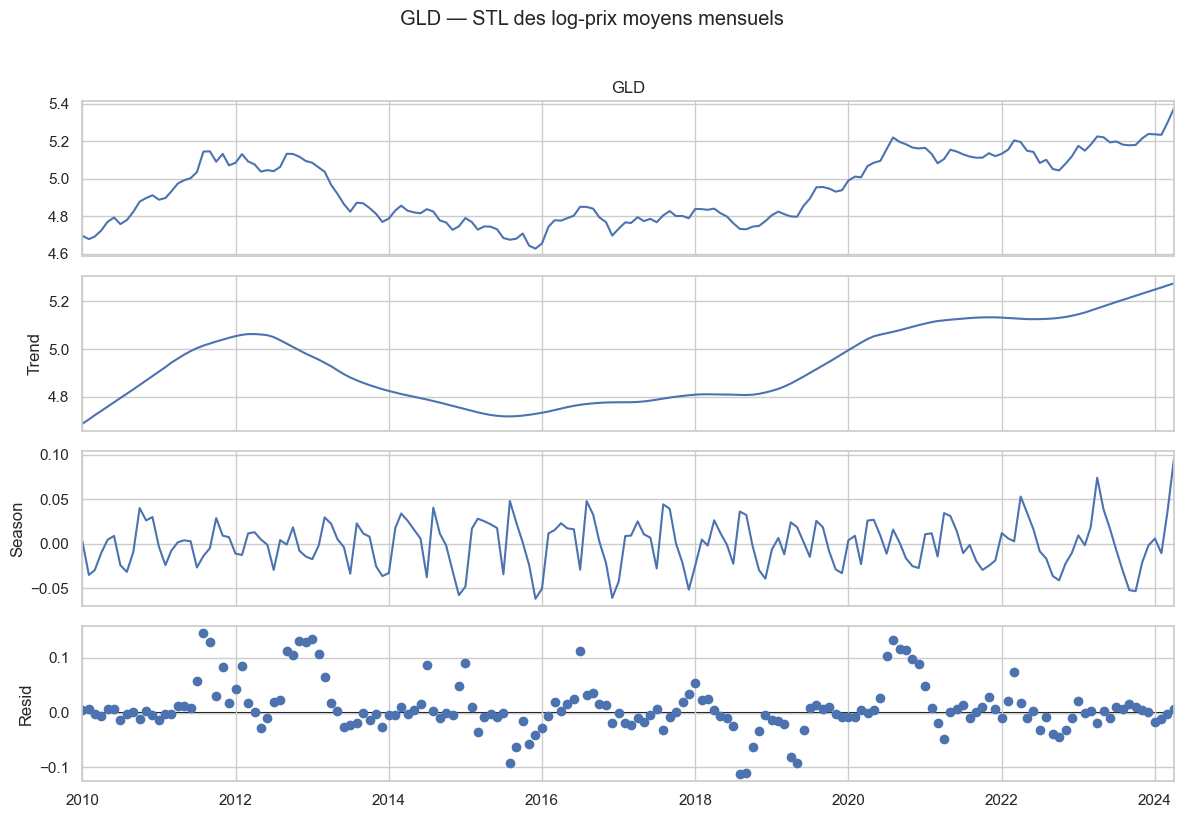

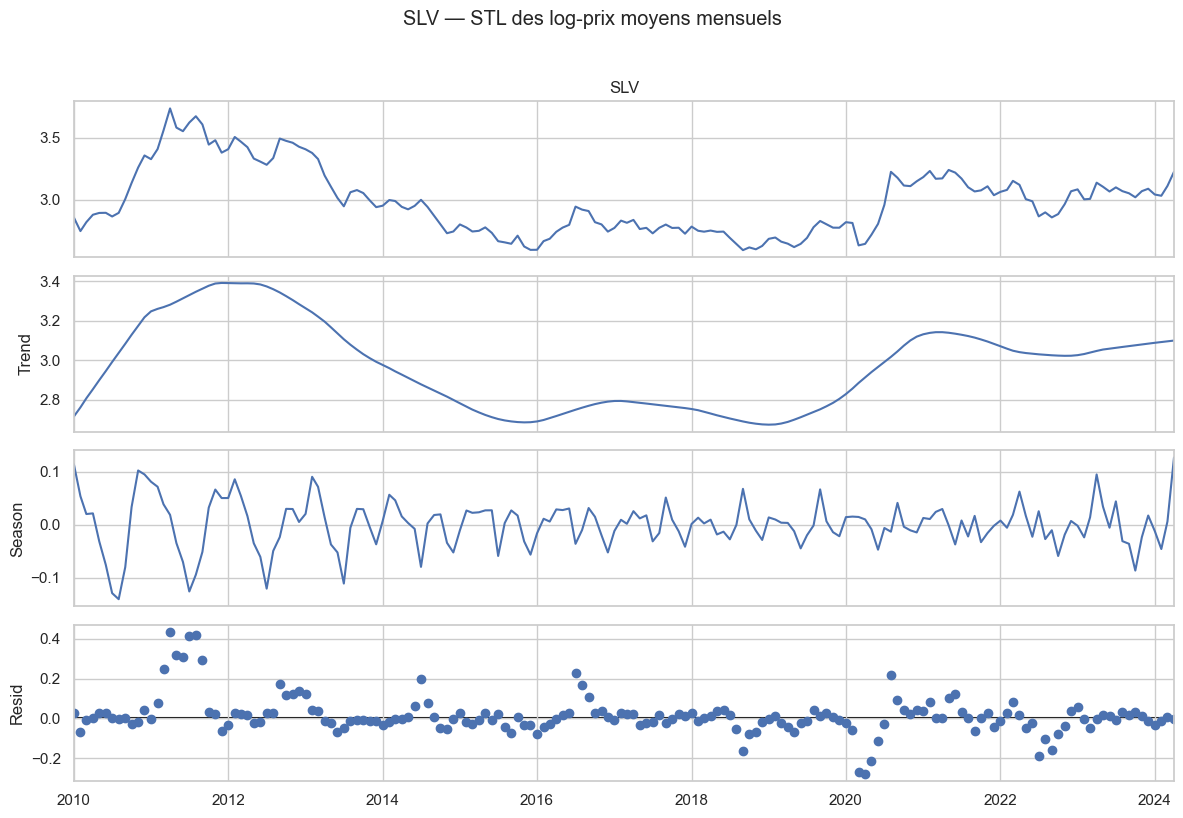

In [18]:
from statsmodels.tsa.seasonal import STL

# Exclure le dernier mois s'il n'est pas entièrement dans l'apprentissage.
dernier_mois = prix_train.index[-1].to_period("M")
train_mois_complets = prix_train.loc[
    prix_train.index.to_period("M") < dernier_mois
]

# Utiliser une grille mensuelle pour explorer un éventuel cycle annuel.
prix_mensuels = train_mois_complets.resample("MS").mean()
log_prix_mensuels = np.log(prix_mensuels)

if log_prix_mensuels.isna().any().any():
    raise ValueError("Un mois est manquant : vérifier avant la décomposition.")

decompositions = {}

for symbole in ["GLD", "SLV"]:
    decomposition = STL(
        log_prix_mensuels[symbole],
        period=12,
        robust=True
    ).fit()

    decompositions[symbole] = decomposition

    fig = decomposition.plot()
    fig.set_size_inches(12, 8)
    fig.suptitle(
        f"{symbole} — STL des log-prix moyens mensuels",
        y=1.02
    )
    fig.tight_layout()
    fig.savefig(
        dossier_figures / f"05_stl_mensuelle_{symbole}.png",
        dpi=150, bbox_inches="tight"
    )
    plt.show()

    composantes = pd.DataFrame({
        "Log-prix": log_prix_mensuels[symbole],
        "Tendance": decomposition.trend,
        "Saisonnalité": decomposition.seasonal,
        "Résidu": decomposition.resid
    })

    composantes.to_csv(
        dossier_prepare / f"stl_mensuelle_{symbole}.csv",
        index_label="Date"
    )


In [19]:
# Comparer l'amplitude des composantes sans supposer une saisonnalité forte.
resume_stl = []

for symbole, decomposition in decompositions.items():
    resume_stl.append({
        "Actif": symbole,
        "Écart-type tendance": np.std(decomposition.trend, ddof=1),
        "Écart-type saisonnalité": np.std(decomposition.seasonal, ddof=1),
        "Écart-type résidu": np.std(decomposition.resid, ddof=1),
        "Amplitude saisonnière": np.ptp(decomposition.seasonal)
    })

resume_stl = pd.DataFrame(resume_stl).set_index("Actif")
print(resume_stl.round(4).to_string())


       Écart-type tendance  Écart-type saisonnalité  Écart-type résidu  Amplitude saisonnière
Actif                                                                                        
GLD                 0.1618                   0.0262             0.0449                 0.1571
SLV                 0.2182                   0.0443             0.0976                 0.2677


### Interprétation de la décomposition STL

La tendance présente l’écart-type le plus élevé pour les deux actifs.
La composante saisonnière extraite est relativement faible, tandis
que SLV présente une dispersion résiduelle supérieure à celle de GLD.

Cette décomposition exploratoire impose une période de 12 mois :
elle ne prouve pas l’existence d’une saisonnalité annuelle stable.
Elle ne justifie pas, à elle seule, un SARIMA sur les données quotidiennes.### Interprétation de la décomposition STL

La tendance présente l’écart-type le plus élevé pour les deux actifs.
La composante saisonnière extraite est relativement faible, tandis
que SLV présente une dispersion résiduelle supérieure à celle de GLD.

Cette décomposition exploratoire impose une période de 12 mois :
elle ne prouve pas l’existence d’une saisonnalité annuelle stable.
Elle ne justifie pas, à elle seule, un SARIMA sur les données quotidiennes.


## 5. Modélisation classique

### 5.1. ARIMA : sélection et diagnostics

In [20]:
from statsmodels.tsa.arima.model import ARIMA

ordres = [(0, 1, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1)]
modeles_arima = {}
comparaison = []

for symbole in ["GLD", "SLV"]:
    # Utiliser un index de séances ; conserver les dates dans prix_train.
    serie = log_prix_train[symbole].reset_index(drop=True)

    for ordre in ordres:
        for tendance in ["n", "t"]:
            # Avec d=1, une tendance linéaire des niveaux représente une dérive.
            modele = ARIMA(
                serie,
                order=ordre,
                trend=tendance
            ).fit()

            cle = (symbole, ordre, tendance)
            modeles_arima[cle] = modele

            comparaison.append({
                "Actif": symbole,
                "Ordre": str(ordre),
                "Dérive": tendance == "t",
                "AIC": modele.aic,
                "BIC": modele.bic,
                "Convergence": modele.mle_retvals.get("converged", False)
            })

comparaison_arima = pd.DataFrame(comparaison)

for symbole in ["GLD", "SLV"]:
    print(f"\n--- {symbole} ---")
    display(
        comparaison_arima[
            comparaison_arima["Actif"] == symbole
        ].sort_values("AIC").round(3)
    )

comparaison_arima.to_csv(
    dossier_prepare / "comparaison_arima_manuels.csv",
    index=False
)


c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



--- GLD ---


,Actif,Ordre,Dérive,AIC,BIC,Convergence
0,GLD,"(0, 1, 0)",False,-23232.432,-23226.238,True
1,GLD,"(0, 1, 0)",True,-23231.830,-23219.442,True
4,GLD,"(0, 1, 1)",False,-23230.658,-23218.269,True
2,GLD,"(1, 1, 0)",False,-23230.653,-23218.265,True
5,GLD,"(0, 1, 1)",True,-23230.081,-23211.498,True
3,GLD,"(1, 1, 0)",True,-23230.076,-23211.493,True
6,GLD,"(1, 1, 1)",False,-23228.165,-23209.583,False
7,GLD,"(1, 1, 1)",True,-23227.646,-23202.869,True



--- SLV ---


,Actif,Ordre,Dérive,AIC,BIC,Convergence
8,SLV,"(0, 1, 0)",False,-18728.300,-18722.106,True
10,SLV,"(1, 1, 0)",False,-18727.501,-18715.112,True
12,SLV,"(0, 1, 1)",False,-18727.472,-18715.083,True
9,SLV,"(0, 1, 0)",True,-18726.502,-18714.114,True
11,SLV,"(1, 1, 0)",True,-18725.696,-18707.113,True
13,SLV,"(0, 1, 1)",True,-18725.667,-18707.085,True
14,SLV,"(1, 1, 1)",False,-18724.556,-18705.974,True
15,SLV,"(1, 1, 1)",True,-18722.751,-18697.974,True


In [21]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera

modeles_retenus = {}
residus_arima = {}
diagnostics = []

for symbole in ["GLD", "SLV"]:
    modele = modeles_arima[(symbole, (0, 1, 0), "n")]
    modeles_retenus[symbole] = modele

    # Exclure l'initialisation du filtre pour ne pas fausser les tests.
    debut = max(1, int(modele.loglikelihood_burn))
    residus = pd.Series(
        np.asarray(modele.resid)[debut:],
        index=prix_train.index[debut:],
        name=symbole
    ).dropna()

    residus_arima[symbole] = residus

    lb = acorr_ljungbox(
        residus, lags=[10, 20], model_df=0, return_df=True
    )
    jb_stat, jb_p, _, _ = jarque_bera(residus)
    arch_stat, arch_p, _, _ = het_arch(residus, nlags=10)

    diagnostics.append({
        "Actif": symbole,
        "Ljung-Box p (10)": lb.loc[10, "lb_pvalue"],
        "Ljung-Box p (20)": lb.loc[20, "lb_pvalue"],
        "Jarque-Bera statistique": jb_stat,
        "Jarque-Bera p": jb_p,
        "ARCH-LM statistique": arch_stat,
        "ARCH-LM p (10)": arch_p
    })

diagnostics_arima = pd.DataFrame(diagnostics).set_index("Actif")

print(diagnostics_arima.to_string(float_format=lambda x: f"{x:.6g}"))

diagnostics_arima.to_csv(
    dossier_prepare / "diagnostics_arima_manuels.csv"
)


       Ljung-Box p (10)  Ljung-Box p (20)  Jarque-Bera statistique  Jarque-Bera p  ARCH-LM statistique  ARCH-LM p (10)
Actif                                                                                                                 
GLD            0.670754          0.734298                  3903.39              0               142.83      1.1079e-25
SLV            0.414213         0.0486754                   7845.7              0              255.727      3.3882e-49


c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


### Diagnostic des résidus des ARIMA manuels

Pour GLD, Ljung–Box ne rejette pas l’absence d’autocorrélation
aux retards 10 et 20.

Pour SLV, l’absence d’autocorrélation n’est pas rejetée à 10 retards,
mais elle est rejetée marginalement à 20 retards (p = 0,0487).
Le modèle de moyenne reste donc à examiner.

Jarque–Bera rejette la normalité des résidus des deux actifs.
ARCH-LM détecte des effets de variance conditionnelle pour les deux,
ce qui motive l’estimation de modèles GARCH.

Les intervalles fondés sur une variance constante et des erreurs
gaussiennes devront être interprétés avec prudence.


In [22]:
import pmdarima as pm

modeles_auto = {}
resume_auto = []

for symbole in ["GLD", "SLV"]:
    print(f"\n--- Recherche automatique : {symbole} ---", flush=True)

    # Chercher des ordres modestes uniquement sur l’apprentissage.
    modele = pm.auto_arima(
        log_prix_train[symbole].to_numpy(),
        d=1,
        start_p=0,
        start_q=0,
        max_p=3,
        max_q=3,
        seasonal=False,
        information_criterion="aic",
        with_intercept="auto",
        stepwise=True,
        maxiter=100,
        suppress_warnings=False,
        error_action="warn",
        trace=True
    )

    modeles_auto[symbole] = modele

    resume_auto.append({
        "Actif": symbole,
        "Ordre automatique": str(modele.order),
        "Dérive": bool(modele.with_intercept),
        "AIC": modele.aic(),
        "BIC": modele.bic(),
        "Convergence": modele.arima_res_.mle_retvals.get(
            "converged", False
        )
    })

resume_auto = pd.DataFrame(resume_auto)
display(resume_auto.round(3))

resume_auto.to_csv(
    dossier_prepare / "selection_auto_arima.csv",
    index=False
)



--- Recherche automatique : GLD ---
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-23231.831, Time=0.44 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-23230.076, Time=0.68 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-23230.081, Time=0.34 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-23232.432, Time=0.25 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-23227.607, Time=0.48 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 2.198 seconds

--- Recherche automatique : SLV ---
Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-18726.503, Time=0.43 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-18725.696, Time=0.33 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-18725.667, Time=2.09 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-18728.300, Time=0.21 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-18722.753, Time=1.43 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 4.504 seconds


,Actif,Ordre automatique,Dérive,AIC,BIC,Convergence
0,GLD,"(0, 1, 0)",False,-23232.432,-23226.238,True
1,SLV,"(0, 1, 0)",False,-18728.300,-18722.106,True


### Comparaison des sélections manuelle et automatique

La recherche automatique progressive, avec d = 1 et p, q limités à 3,
retient ARIMA(0,1,0) sans dérive pour les deux actifs, comme la
comparaison manuelle.

Ce résultat soutient un modèle simple de marche aléatoire des log-prix.
Il ne démontre pas sa supériorité en prévision sur les données test.

Les diagnostics restent essentiels : des effets ARCH sont détectés
pour les deux actifs et une autocorrélation marginale persiste pour
SLV à 20 retards.


### 5.2. VAR et dépendances prédictives

In [23]:
from statsmodels.tsa.api import VAR

# Utiliser les rendements stationnaires des deux actifs sur l’apprentissage.
donnees_var = rendements_train[["GLD", "SLV"]].reset_index(drop=True)

modele_var = VAR(donnees_var)

# Comparer jusqu’à 10 séances passées sans utiliser la période test.
selection_var = modele_var.select_order(maxlags=10, trend="c")

print(selection_var.summary())
print("\nOrdres sélectionnés :", selection_var.selected_orders)

table_selection_var = pd.DataFrame(selection_var.ics)
table_selection_var.index.name = "Retard"

table_selection_var.to_csv(
    dossier_prepare / "selection_retards_var.csv"
)


 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0      0.1712*     0.1747*      1.187*     0.1725*
1       0.1717      0.1820       1.187      0.1753
2       0.1728      0.1900       1.189      0.1789
3       0.1739      0.1979       1.190      0.1824
4       0.1747      0.2055       1.191      0.1857
5       0.1763      0.2140       1.193      0.1897
6       0.1772      0.2218       1.194      0.1931
7       0.1780      0.2295       1.195      0.1963
8       0.1780      0.2364       1.195      0.1988
9       0.1774      0.2426       1.194      0.2006
10      0.1781      0.2502       1.195      0.2038
--------------------------------------------------

Ordres sélectionnés : {'aic': np.int64(0), 'bic': np.int64(0), 'hqic': np.int64(0), 'fpe': np.int64(0)}


In [24]:
# Respecter le choix des critères d’information.
var_selectionne = modele_var.fit(0, trend="c")

# Examiner un retard pour tester une éventuelle information prédictive croisée.
var_complementaire = modele_var.fit(1, trend="c")

print(var_complementaire.summary())


  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 09, Oct, 2026
Time:                     13:06:07
--------------------------------------------------------------------
No. of Equations:         2.00000    BIC:                   0.182405
Nobs:                     3619.00    HQIC:                  0.175795
Log likelihood:          -10575.8    FPE:                    1.18784
AIC:                     0.172136    Det(Omega_mle):         1.18587
--------------------------------------------------------------------
Results for equation GLD
            coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------
const          0.019489         0.016255            1.199           0.231
L1.GLD        -0.016823         0.027162           -0.619           0.536
L1.SLV         0.005837         0.014579            0.400           0.689

Results for equ

In [25]:
# Tester si le passé d’un actif aide à prévoir l’autre,
# au-delà du passé de l’actif à prévoir.
resultats_granger = []

for source, cible in [("SLV", "GLD"), ("GLD", "SLV")]:
    test = var_complementaire.test_causality(
        caused=cible,
        causing=[source],
        kind="f"
    )

    resultats_granger.append({
        "Direction": f"{source} → {cible}",
        "Ordre VAR": 1,
        "Statistique F": test.test_statistic,
        "p-value": test.pvalue
    })

table_granger = pd.DataFrame(resultats_granger)
display(table_granger.round(6))

table_granger.to_csv(
    dossier_prepare / "granger_var1_complementaire.csv",
    index=False
)


,Direction,Ordre VAR,Statistique F,p-value
0,SLV → GLD,1,0.160327,0.688868
1,GLD → SLV,1,0.178588,0.672602


### Sélection du VAR et tests de Granger

AIC, BIC, HQIC et FPE sélectionnent tous VAR(0) parmi les ordres
0 à 10. VAR(1) est étudié comme modèle complémentaire pour les
tests de Granger.

Avec un retard, les tests ne rejettent pas l’absence de causalité
de Granger de SLV vers GLD (p = 0,6889), ni de GLD vers SLV
(p = 0,6726).

Ces résultats concernent une dépendance prédictive linéaire à
une séance. Ils ne prouvent pas l’absence de toute relation
entre les actifs. Les effets ARCH invitent à rester prudent
sur les p-values classiques.


In [26]:
from statsmodels.stats.diagnostic import het_arch

diagnostics_var = []

for nom, resultat in [
    ("VAR(0) sélectionné", var_selectionne),
    ("VAR(1) complémentaire", var_complementaire)
]:
    # Tester conjointement l’autocorrélation et la normalité des résidus.
    blancheur = resultat.test_whiteness(nlags=20, adjusted=True)
    normalite = resultat.test_normality()

    for symbole in ["GLD", "SLV"]:
        # Examiner les effets ARCH séparément dans chaque équation.
        residus = resultat.resid[symbole]
        arch_stat, arch_p, _, _ = het_arch(
            residus,
            nlags=10,
            ddof=resultat.k_ar + 1
        )

        diagnostics_var.append({
            "Modèle": nom,
            "Équation": symbole,
            "Blancheur multivariée p (20)": blancheur.pvalue,
            "Normalité multivariée p": normalite.pvalue,
            "ARCH-LM p (10)": arch_p
        })

table_diagnostics_var = pd.DataFrame(diagnostics_var)

print(
    table_diagnostics_var.to_string(
        index=False,
        float_format=lambda x: f"{x:.6g}"
    )
)

table_diagnostics_var.to_csv(
    dossier_prepare / "diagnostics_var.csv",
    index=False
)


               Modèle Équation  Blancheur multivariée p (20)  Normalité multivariée p  ARCH-LM p (10)
   VAR(0) sélectionné      GLD                     0.0101769                        0      1.3744e-25
   VAR(0) sélectionné      SLV                     0.0101769                        0     4.58448e-49
VAR(1) complémentaire      GLD                    0.00921871                        0     4.04133e-25
VAR(1) complémentaire      SLV                    0.00921871                        0      2.8611e-50


c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


### Diagnostic des VAR

Les tests de blancheur multivariée à 20 retards rejettent
l’absence d’autocorrélation résiduelle pour VAR(0) et VAR(1).
VAR(1) ne résout donc pas la dépendance détectée.

La normalité multivariée est rejetée et des effets ARCH sont
détectés dans chaque équation. VAR(0), sélectionné par les critères
d’information, reste une référence simple avec ces limites explicites.


### 5.3. Cointégration

In [27]:
from statsmodels.tsa.stattools import coint

resultats_coint = []

# Spécification principale : GLD expliqué par SLV, avec constante.
# Inversion de la régression : contrôle de sensibilité, pas un second
# essai destiné à obtenir absolument une p-value significative.
for cible, explicative in [("GLD", "SLV"), ("SLV", "GLD")]:
    statistique, p_value, valeurs_critiques = coint(
        log_prix_train[cible],
        log_prix_train[explicative],
        trend="c",
        autolag="aic"
    )

    resultats_coint.append({
        "Régression": f"{cible} ~ {explicative}",
        "Statistique EG": statistique,
        "p-value": p_value,
        "Valeur critique 5 %": valeurs_critiques[1]
    })

table_coint = pd.DataFrame(resultats_coint)
display(table_coint.round(6))

table_coint.to_csv(
    dossier_prepare / "cointegration_engle_granger.csv",
    index=False
)


,Régression,Statistique EG,p-value,Valeur critique 5 %
0,GLD ~ SLV,-0.659857,0.950799,-3.337818
1,SLV ~ GLD,-1.792335,0.633438,-3.337818


### Conclusion sur la cointégration

Le test d’Engle–Granger avec constante ne rejette pas l’absence
de cointégration entre les log-prix de GLD et SLV sur l’apprentissage.

La p-value est de 0,9508 pour GLD expliqué par SLV et de 0,6334
pour la régression inversée, utilisée comme contrôle de sensibilité.

Malgré une forte corrélation des rendements, aucune relation
d’équilibre de long terme n’est détectée avec cette spécification.
Nous ne retenons donc pas de VECM à ce stade.


## 6. Modélisation de la volatilité : GARCH(1,1)

Les tests ARCH-LM indiquent une variance conditionnelle variable.
Nous estimons un GARCH(1,1) sur les rendements logarithmiques
exprimés en pourcentage, uniquement sur l’apprentissage.

La moyenne est fixée à zéro pour rester cohérent avec l’ARIMA
sans dérive. Une distribution de Student est utilisée pour
représenter les queues épaisses observées.

La dépendance résiduelle détectée auparavant reste une limite
à vérifier après estimation.


In [28]:
from arch import arch_model
print("Bibliothèque GARCH prête.")


Bibliothèque GARCH prête.


In [29]:
modeles_garch = {}
resume_garch = []

for symbole in ["GLD", "SLV"]:
    # Modéliser la variance des rendements sans ajouter de dérive.
    modele = arch_model(
        rendements_train[symbole],
        mean="Zero",
        vol="GARCH",
        p=1,
        q=1,
        dist="t",
        rescale=False
    )

    resultat = modele.fit(disp="off")
    modeles_garch[symbole] = resultat

    parametres = resultat.params

    resume_garch.append({
        "Actif": symbole,
        "Omega": parametres["omega"],
        "Alpha": parametres["alpha[1]"],
        "Beta": parametres["beta[1]"],
        "Alpha + Beta": (
            parametres["alpha[1]"] + parametres["beta[1]"]
        ),
        "Nu (Student)": parametres["nu"],
        "AIC": resultat.aic,
        "BIC": resultat.bic,
        "Convergence": resultat.convergence_flag == 0
    })

    print(f"\n--- {symbole} ---")
    print(resultat.summary())

table_garch = pd.DataFrame(resume_garch).set_index("Actif")
display(table_garch.round(4))

table_garch.to_csv(
    dossier_prepare / "parametres_garch11_student.csv"
)



--- GLD ---
                          Zero Mean - GARCH Model Results                           
Dep. Variable:                          GLD   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -4706.93
Distribution:      Standardized Student's t   AIC:                           9421.85
Method:                  Maximum Likelihood   BIC:                           9446.63
                                              No. Observations:                 3620
Date:                      Fri, Oct 09 2026   Df Residuals:                     3620
Time:                              13:06:08   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
--------------------------------------------------------------------

,Omega,Alpha,Beta,Alpha + Beta,Nu (Student),AIC,BIC,Convergence
Actif,,,,,,,,
GLD,0.0115,0.0414,0.9477,0.9891,4.8926,9421.8547,9446.6316,True
SLV,0.0179,0.0335,0.9630,0.9965,4.1223,13546.7186,13571.4955,True


In [30]:
diagnostics_garch = []

for symbole, resultat in modeles_garch.items():
    # Retirer l’effet de la volatilité estimée des erreurs.
    z = resultat.std_resid.dropna()

    # Vérifier la dépendance dans les erreurs et dans leur amplitude.
    lb_z = acorr_ljungbox(
        z, lags=[10, 20], model_df=0, return_df=True
    )
    lb_z2 = acorr_ljungbox(
        z**2, lags=[10, 20], model_df=0, return_df=True
    )
    arch_stat, arch_p, _, _ = het_arch(z, nlags=10)

    diagnostics_garch.append({
        "Actif": symbole,
        "Ljung-Box z p (10)": lb_z.loc[10, "lb_pvalue"],
        "Ljung-Box z p (20)": lb_z.loc[20, "lb_pvalue"],
        "Ljung-Box z² p (10)": lb_z2.loc[10, "lb_pvalue"],
        "Ljung-Box z² p (20)": lb_z2.loc[20, "lb_pvalue"],
        "ARCH-LM p (10)": arch_p
    })

table_diagnostics_garch = pd.DataFrame(
    diagnostics_garch
).set_index("Actif")

print(
    table_diagnostics_garch.to_string(
        float_format=lambda x: f"{x:.6g}"
    )
)

table_diagnostics_garch.to_csv(
    dossier_prepare / "diagnostics_garch11_student.csv"
)


       Ljung-Box z p (10)  Ljung-Box z p (20)  Ljung-Box z² p (10)  Ljung-Box z² p (20)  ARCH-LM p (10)
Actif                                                                                                  
GLD              0.860699            0.908176            0.0325691             0.185286       0.0488553
SLV               0.11358            0.089224          2.06415e-07          7.24842e-06     4.68422e-07


c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [31]:
# Comparer quelques ordres supérieurs, motivés par les diagnostics.
# Garder le même échantillon, la moyenne nulle et la loi de Student.
candidats_garch = {}
comparaison_garch = []

for symbole in ["GLD", "SLV"]:
    for p, q in [(1, 1), (2, 1), (1, 2)]:
        if (p, q) == (1, 1):
            resultat = modeles_garch[symbole]
        else:
            resultat = arch_model(
                rendements_train[symbole],
                mean="Zero",
                vol="GARCH",
                p=p,
                q=q,
                dist="t",
                rescale=False
            ).fit(disp="off")

        candidats_garch[(symbole, p, q)] = resultat

        z = resultat.std_resid.dropna()

        lb_z = acorr_ljungbox(
            z, lags=[10, 20], return_df=True
        )
        lb_z2 = acorr_ljungbox(
            z**2, lags=[10, 20], return_df=True
        )
        _, arch_p, _, _ = het_arch(z, nlags=10)

        persistance = sum(
            valeur
            for nom, valeur in resultat.params.items()
            if nom.startswith(("alpha[", "beta["))
        )

        comparaison_garch.append({
            "Actif": symbole,
            "Modèle": f"GARCH({p},{q})",
            "AIC": resultat.aic,
            "BIC": resultat.bic,
            "Persistance": persistance,
            "LB z p (10)": lb_z.loc[10, "lb_pvalue"],
            "LB z p (20)": lb_z.loc[20, "lb_pvalue"],
            "LB z² p (10)": lb_z2.loc[10, "lb_pvalue"],
            "LB z² p (20)": lb_z2.loc[20, "lb_pvalue"],
            "ARCH p (10)": arch_p,
            "Convergence": resultat.convergence_flag == 0
        })

comparaison_garch = pd.DataFrame(comparaison_garch)

for symbole in ["GLD", "SLV"]:
    print(f"\n--- {symbole} ---")
    print(
        comparaison_garch[
            comparaison_garch["Actif"] == symbole
        ].sort_values("AIC").to_string(
            index=False,
            float_format=lambda x: f"{x:.6g}"
        )
    )

comparaison_garch.to_csv(
    dossier_prepare / "comparaison_ordres_garch.csv",
    index=False
)


c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\Use


--- GLD ---
Actif     Modèle     AIC     BIC  Persistance  LB z p (10)  LB z p (20)  LB z² p (10)  LB z² p (20)  ARCH p (10)  Convergence
  GLD GARCH(2,1) 9419.43  9450.4     0.986662     0.828021     0.902235   1.44785e-05   0.000904026  1.75601e-05         True
  GLD GARCH(1,1) 9421.85 9446.63     0.989058     0.860699     0.908176     0.0325691      0.185286    0.0488553         True
  GLD GARCH(1,2) 9423.85 9454.83     0.989058     0.860698     0.908172     0.0325126      0.185115    0.0487837         True

--- SLV ---
Actif     Modèle     AIC     BIC  Persistance  LB z p (10)  LB z p (20)  LB z² p (10)  LB z² p (20)  ARCH p (10)  Convergence
  SLV GARCH(1,1) 13546.7 13571.5     0.996469      0.11358     0.089224   2.06415e-07   7.24842e-06  4.68422e-07         True
  SLV GARCH(1,2) 13548.1   13579     0.995571     0.122936    0.0966948   1.61006e-06   3.52063e-05  4.03108e-06         True
  SLV GARCH(2,1) 13548.7 13579.7     0.996469     0.113581    0.0892248   2.06467e-07      7

c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


In [32]:
modeles_gjr = {}
resume_gjr = []

for symbole in ["GLD", "SLV"]:
    # Tester une réponse asymétrique de la variance aux chocs.
    resultat = arch_model(
        rendements_train[symbole],
        mean="Zero",
        vol="GARCH",
        p=1,
        o=1,
        q=1,
        dist="t",
        rescale=False
    ).fit(disp="off")

    modeles_gjr[symbole] = resultat
    z = resultat.std_resid.dropna()

    lb_z = acorr_ljungbox(z, lags=[10, 20], return_df=True)
    lb_z2 = acorr_ljungbox(z**2, lags=[10, 20], return_df=True)
    _, arch_p, _, _ = het_arch(z, nlags=10)

    params = resultat.params

    resume_gjr.append({
        "Actif": symbole,
        "AIC": resultat.aic,
        "BIC": resultat.bic,
        "Gamma": params["gamma[1]"],
        "Gamma p-value": resultat.pvalues["gamma[1]"],
        "Persistance": (
            params["alpha[1]"]
            + params["beta[1]"]
            + params["gamma[1]"] / 2
        ),
        "LB z p (10)": lb_z.loc[10, "lb_pvalue"],
        "LB z p (20)": lb_z.loc[20, "lb_pvalue"],
        "LB z² p (10)": lb_z2.loc[10, "lb_pvalue"],
        "LB z² p (20)": lb_z2.loc[20, "lb_pvalue"],
        "ARCH p (10)": arch_p,
        "Convergence": resultat.convergence_flag == 0
    })

table_gjr = pd.DataFrame(resume_gjr).set_index("Actif")

print(table_gjr.to_string(float_format=lambda x: f"{x:.6g}"))

table_gjr.to_csv(
    dossier_prepare / "diagnostics_gjr_garch_student.csv"
)


          AIC     BIC      Gamma  Gamma p-value  Persistance  LB z p (10)  LB z p (20)  LB z² p (10)  LB z² p (20)  ARCH p (10)  Convergence
Actif                                                                                                                                       
GLD   9416.37 9447.34 -0.0275672     0.00859152     0.990145     0.884535     0.918559   0.000525045    0.00897522   0.00100337         True
SLV   13542.3 13573.2 -0.0221859      0.0174562      0.99686    0.0957114    0.0787141   4.14585e-09   4.37999e-07  1.09277e-08         True


c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
c:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\.venv\lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


### Choix du modèle de volatilité

Les modèles d’ordre supérieur et GJR-GARCH ne suppriment pas
les effets ARCH résiduels. GJR-GARCH améliore l’AIC et révèle
une asymétrie négative significative, mais le BIC préfère
GARCH(1,1) pour les deux actifs.

GARCH(1,1) avec innovations de Student est conservé comme référence
simple. Sa validation reste partielle : les effets ARCH résiduels
sont marginaux pour GLD et nettement significatifs pour SLV.

La volatilité estimée sera donc présentée comme une approximation
utile, sans prétendre décrire entièrement le risque.


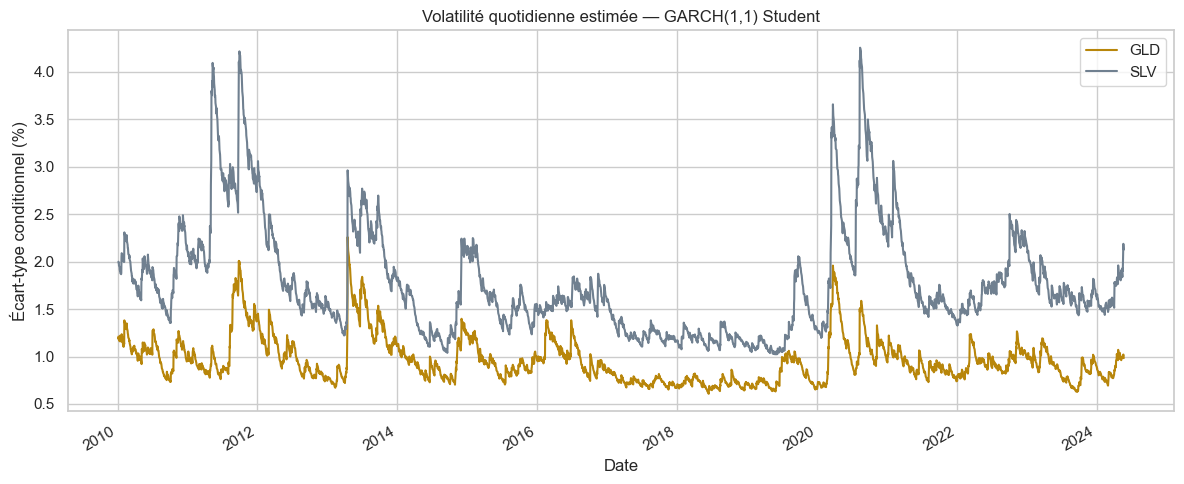


--- GLD : cinq pics de volatilité estimée ---
Date
2013-04-16    2.2592
2013-04-17    2.2139
2013-04-18    2.1578
2013-04-19    2.1146
2013-04-22    2.0688

--- SLV : cinq pics de volatilité estimée ---
Date
2020-08-14    4.2557
2020-08-17    4.2265
2020-08-18    4.2184
2011-09-29    4.2173
2011-09-30    4.1958


In [33]:
# Réunir les écarts-types conditionnels quotidiens estimés.
volatilites = pd.DataFrame({
    symbole: resultat.conditional_volatility
    for symbole, resultat in modeles_garch.items()
})

ax = volatilites.plot(
    figsize=(12, 5),
    color=["darkgoldenrod", "slategray"],
    title="Volatilité quotidienne estimée — GARCH(1,1) Student"
)

ax.set_ylabel("Écart-type conditionnel (%)")
ax.set_xlabel("Date")

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(
    dossier_figures / "06_volatilites_garch11.png",
    dpi=150, bbox_inches="tight"
)
plt.show()

volatilites.to_csv(
    dossier_prepare / "volatilites_garch11_train.csv",
    index_label="Date"
)

# Identifier les périodes de volatilité estimée la plus élevée.
for symbole in ["GLD", "SLV"]:
    print(f"\n--- {symbole} : cinq pics de volatilité estimée ---")
    print(volatilites[symbole].nlargest(5).round(4).to_string())


### Interprétation des pics de volatilité

Les cinq valeurs les plus élevées de GLD se regroupent entre
le 16 et le 22 avril 2013, après la forte baisse du 15 avril.

Pour SLV, les pics se situent en août 2020 et septembre 2011,
durant des épisodes documentés de fortes fluctuations des métaux.

Ce regroupement illustre la persistance de la volatilité estimée.
Les cinq pics ne constituent pas nécessairement cinq événements
distincts, mais plusieurs séances appartenant aux mêmes épisodes.

Ces correspondances historiques ne prouvent pas une causalité.
Les courbes représentent une estimation sur l’apprentissage,
et les diagnostics indiquent des effets ARCH résiduels.


## 7. Réseaux récurrents : LSTM et GRU

Nous utilisons les rendements logarithmiques quotidiens de GLD et SLV
pour prévoir conjointement leurs rendements à la séance suivante.

Les 90 % initiaux de l’historique, déjà réservés à l’apprentissage,
sont séparés chronologiquement : 80 % pour entraîner les réseaux
et 20 % pour les valider. Le test final reste réservé à l’évaluation.

Une fenêtre initiale de 30 séances est retenue. Ce choix devra
être évalué par validation temporelle.


In [34]:
import tensorflow as tf
import sklearn

print("TensorFlow :", tf.__version__)
print("Scikit-learn :", sklearn.__version__)
print("Environnement prêt pour LSTM et GRU.")


TensorFlow : 2.21.0
Scikit-learn : 1.7.2
Environnement prêt pour LSTM et GRU.


In [35]:
# Réserver la fin de l’apprentissage pour valider les réseaux
# sans utiliser le test final pour choisir leurs paramètres.
fenetre = 30
n_fit = int(len(rendements_train) * 0.80)

rendements_fit = rendements_train.iloc[:n_fit].copy()
rendements_validation = rendements_train.iloc[n_fit:].copy()

for nom, tableau in [
    ("Entraînement réseau", rendements_fit),
    ("Validation", rendements_validation)
]:
    print(
        f"{nom} : {len(tableau)} séances | "
        f"{tableau.index.min().date()} → "
        f"{tableau.index.max().date()}"
    )

print("\nFenêtre :", fenetre, "séances")
print("Le test final contient", len(prix_test), "séances.")


Entraînement réseau : 2896 séances | 2010-01-05 → 2021-07-07
Validation : 724 séances | 2021-07-08 → 2024-05-22

Fenêtre : 30 séances
Le test final contient 403 séances.


### Préparation des entrées

Les rendements sont standardisés avec un StandardScaler ajusté
uniquement sur l’entraînement, afin d’éviter une fuite d’information.

Chaque entrée contient les rendements des deux actifs pendant
les 30 séances précédentes. La cible contient leurs rendements
à la séance suivante.

Les premières séquences de validation utilisent les dernières
observations d’entraînement, disponibles avant la date à prévoir.


In [36]:
from sklearn.preprocessing import StandardScaler

# Apprendre l’échelle uniquement sur l’entraînement pour éviter
# que les données de validation influencent la préparation.
scaler_rendements = StandardScaler()
scaler_rendements.fit(rendements_fit[["GLD", "SLV"]])

rendements_scaled = scaler_rendements.transform(
    rendements_train[["GLD", "SLV"]]
).astype(np.float32)

# Construire chaque séquence avec les observations antérieures
# à sa cible, en conservant les dates pour les évaluations.
X, y, dates_cibles = [], [], []

for t in range(fenetre, len(rendements_scaled)):
    X.append(rendements_scaled[t - fenetre:t])
    y.append(rendements_scaled[t])
    dates_cibles.append(rendements_train.index[t])

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
dates_cibles = pd.DatetimeIndex(dates_cibles)

# Séparer selon la date de la cible ; les premières séquences
# de validation utilisent les dernières séances d’entraînement.
masque_fit = dates_cibles < rendements_validation.index[0]

X_fit, y_fit = X[masque_fit], y[masque_fit]
X_val, y_val = X[~masque_fit], y[~masque_fit]

dates_fit = dates_cibles[masque_fit]
dates_val = dates_cibles[~masque_fit]

assert dates_fit.max() < dates_val.min()
assert np.isfinite(X).all() and np.isfinite(y).all()

print("X_fit :", X_fit.shape)
print("y_fit :", y_fit.shape)
print("X_val :", X_val.shape)
print("y_val :", y_val.shape)
print("\nPremière cible de validation :", dates_val[0].date())


X_fit : (2866, 30, 2)
y_fit : (2866, 2)
X_val : (724, 30, 2)
y_val : (724, 2)

Première cible de validation : 2021-07-08


### Architecture et entraînement du LSTM

Le réseau comprend une couche LSTM de 32 unités et une couche
Dense à deux sorties, soit 4 546 paramètres entraînables.

Nous utilisons l’optimiseur Adam et une perte quadratique (MSE).
L’entraînement conserve l’ordre des séquences, sans mélange.

Un arrêt anticipé surveille la MSE de validation avec une patience
de 10 époques et restaure les poids de la meilleure époque.


In [37]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Fixer les graines pour rendre l’entraînement reproductible
# autant que le permettent le matériel et les opérations utilisées.
tf.keras.utils.set_random_seed(42)

# Garder une architecture simple pour limiter le surapprentissage.
modele_lstm = Sequential([
    Input(shape=(fenetre, 2)),
    LSTM(32),
    Dense(2)
])

modele_lstm.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

modele_lstm.summary()

# Arrêter si la validation ne s’améliore plus et restaurer
# les poids de la meilleure époque.
arret_lstm = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

historique_lstm = modele_lstm.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    shuffle=False,
    callbacks=[arret_lstm],
    verbose=0
)

meilleure_epoque = int(
    np.argmin(historique_lstm.history["val_loss"]) + 1
)

print("\nÉpoques exécutées :", len(historique_lstm.history["loss"]))
print("Meilleure époque :", meilleure_epoque)
print(
    "Meilleure MSE de validation (échelle standardisée) :",
    round(min(historique_lstm.history["val_loss"]), 6)
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,546 (17.76 KB)

 Trainable params: 4,546 (17.76 KB)

 Non-trainable params: 0 (0.00 B)


Époques exécutées : 17
Meilleure époque : 7
Meilleure MSE de validation (échelle standardisée) : 0.791077


,Actif,Modèle,MSE,RMSE,MAE
0,GLD,Rendement nul,0.765515,0.874937,0.663019
1,GLD,LSTM,0.761152,0.872440,0.661571
2,SLV,Rendement nul,2.834198,1.683508,1.270828
3,SLV,LSTM,2.825913,1.681045,1.269799


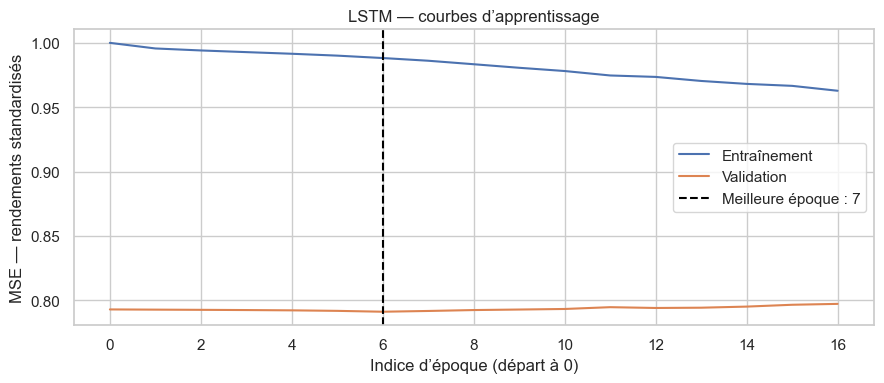

In [38]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Revenir aux rendements en pourcentage pour interpréter les erreurs.
pred_lstm_val_scaled = modele_lstm.predict(X_val, verbose=0)

pred_lstm_val = scaler_rendements.inverse_transform(
    pred_lstm_val_scaled
)
reel_val = scaler_rendements.inverse_transform(y_val)

# Le rendement nul correspond à une prévision de prix inchangé.
pred_zero_val = np.zeros_like(reel_val)

resultats_validation = []

for j, symbole in enumerate(["GLD", "SLV"]):
    for nom, predictions in [
        ("Rendement nul", pred_zero_val),
        ("LSTM", pred_lstm_val)
    ]:
        mse = mean_squared_error(reel_val[:, j], predictions[:, j])

        resultats_validation.append({
            "Actif": symbole,
            "Modèle": nom,
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(
                reel_val[:, j], predictions[:, j]
            )
        })

table_validation_lstm = pd.DataFrame(resultats_validation)
display(table_validation_lstm.round(6))

# Visualiser l’évolution des erreurs et l’époque retenue.
plt.figure(figsize=(9, 4))
plt.plot(historique_lstm.history["loss"], label="Entraînement")
plt.plot(historique_lstm.history["val_loss"], label="Validation")
plt.axvline(
    meilleure_epoque - 1,
    color="black",
    linestyle="--",
    label=f"Meilleure époque : {meilleure_epoque}"
)
plt.xlabel("Indice d’époque (départ à 0)")
plt.ylabel("MSE — rendements standardisés")
plt.title("LSTM — courbes d’apprentissage")
plt.legend()
plt.tight_layout()
plt.show()


### Comparaison du LSTM à la référence naïve

Sur la validation, le LSTM réduit légèrement la MSE par rapport
à une prévision de rendement nul :
- GLD : 0,761152 contre 0,765515, soit une réduction de 0,57 % ;
- SLV : 2,825913 contre 2,834198, soit une réduction de 0,29 %.

Les RMSE et MAE diminuent également, mais les gains restent faibles.
Ces résultats ne démontrent pas encore une supériorité statistique
ni une utilité économique du réseau.

Cette comparaison concerne des prévisions à une séance sur
la validation. Elle devra être complétée par une validation croisée
temporelle et une évaluation sur le test final.


In [39]:
from tensorflow.keras.layers import GRU

# Utiliser les mêmes réglages que le LSTM pour comparer
# les architectures sur les mêmes données.
tf.keras.utils.set_random_seed(42)

modele_gru = Sequential([
    Input(shape=(fenetre, 2)),
    GRU(32),
    Dense(2)
])

modele_gru.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

modele_gru.summary()

arret_gru = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

historique_gru = modele_gru.fit(
    X_fit,
    y_fit,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    shuffle=False,
    callbacks=[arret_gru],
    verbose=0
)

meilleure_epoque_gru = int(
    np.argmin(historique_gru.history["val_loss"]) + 1
)

print("\nÉpoques exécutées :", len(historique_gru.history["loss"]))
print("Meilleure époque :", meilleure_epoque_gru)
print(
    "Meilleure MSE de validation (échelle standardisée) :",
    round(min(historique_gru.history["val_loss"]), 6)
)

# Comparer les trois méthodes dans l’unité d’origine.
pred_gru_val = scaler_rendements.inverse_transform(
    modele_gru.predict(X_val, verbose=0)
)

resultats_validation_reseaux = []

for j, symbole in enumerate(["GLD", "SLV"]):
    for nom, predictions in [
        ("Rendement nul", pred_zero_val),
        ("LSTM", pred_lstm_val),
        ("GRU", pred_gru_val)
    ]:
        mse = mean_squared_error(reel_val[:, j], predictions[:, j])

        resultats_validation_reseaux.append({
            "Actif": symbole,
            "Modèle": nom,
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(
                reel_val[:, j], predictions[:, j]
            )
        })

table_validation_reseaux = pd.DataFrame(
    resultats_validation_reseaux
)

display(table_validation_reseaux.round(6))


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,522 (13.76 KB)

 Trainable params: 3,522 (13.76 KB)

 Non-trainable params: 0 (0.00 B)


Époques exécutées : 23
Meilleure époque : 13
Meilleure MSE de validation (échelle standardisée) : 0.790304


,Actif,Modèle,MSE,RMSE,MAE
0,GLD,Rendement nul,0.765515,0.874937,0.663019
1,GLD,LSTM,0.761152,0.872440,0.661571
2,GLD,GRU,0.760014,0.871788,0.661143
3,SLV,Rendement nul,2.834198,1.683508,1.270828
4,SLV,LSTM,2.825913,1.681045,1.269799
5,SLV,GRU,2.824502,1.680626,1.267368


### Bilan de la validation initiale

Le GRU obtient les meilleures MSE, RMSE et MAE pour GLD et SLV.
Il compte 3 522 paramètres, contre 4 546 pour le LSTM.
L’arrêt anticipé retient l’époque 13 pour le GRU et l’époque 7
pour le LSTM.

Les améliorations face au rendement nul restent faibles :
0,72 % de réduction de MSE pour GLD et 0,34 % pour SLV avec le GRU.
Ce classement devra être vérifié par validation croisée temporelle
et sur le test final.


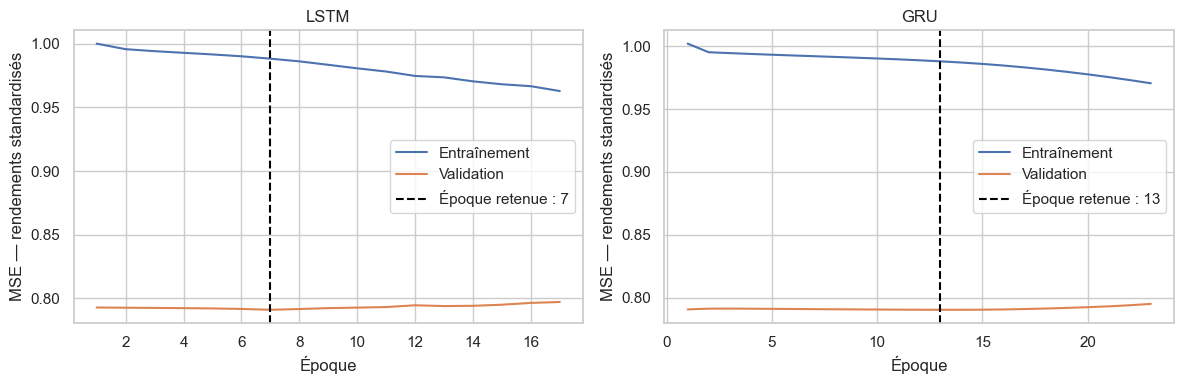

Courbes et historiques sauvegardés.


In [40]:
# Conserver les pertes de la validation initiale et visualiser
# l’évolution de l’apprentissage pour les deux architectures.
fig_pertes, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, nom, historique in [
    (axes[0], "LSTM", historique_lstm),
    (axes[1], "GRU", historique_gru)
]:
    pertes = pd.DataFrame({
        "Epoque": np.arange(1, len(historique.history["loss"]) + 1),
        "MSE entrainement": historique.history["loss"],
        "MSE validation": historique.history["val_loss"]
    })

    meilleure = int(
        pertes.loc[pertes["MSE validation"].idxmin(), "Epoque"]
    )

    ax.plot(
        pertes["Epoque"], pertes["MSE entrainement"],
        label="Entraînement"
    )
    ax.plot(
        pertes["Epoque"], pertes["MSE validation"],
        label="Validation"
    )
    ax.axvline(
        meilleure, color="black", linestyle="--",
        label=f"Époque retenue : {meilleure}"
    )
    ax.set_title(nom)
    ax.set_xlabel("Époque")
    ax.set_ylabel("MSE — rendements standardisés")
    ax.legend()

    pertes.to_csv(
        dossier_prepare / f"historique_apprentissage_{nom.lower()}.csv",
        index=False
    )

fig_pertes.tight_layout()
fig_pertes.savefig(
    dossier_figures / "11_courbes_apprentissage_lstm_gru.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Courbes et historiques sauvegardés.")


Les deux réseaux utilisent une fenêtre de 30 séances, une couche
récurrente de 32 unités et deux sorties. Ces réglages constituent
un point de départ simple, sans recherche exhaustive d’hyperparamètres.

Aucun dropout n’est appliqué dans cette première comparaison.
La complexité limitée et l’arrêt anticipé visent à contenir
le surapprentissage, sans garantir son absence. La validation
temporelle permet d’évaluer la stabilité des performances.


### Validation croisée temporelle

In [41]:
from sklearn.model_selection import TimeSeriesSplit

# Évaluer sur trois blocs successifs avec un historique croissant.
# Utiliser les données non standardisées pour réajuster le scaler
# séparément dans chaque découpage.
donnees_cv = rendements_train[["GLD", "SLV"]].copy()
cv_temporelle = TimeSeriesSplit(n_splits=3, test_size=400)

decoupages_cv = list(cv_temporelle.split(donnees_cv))

for numero, (indices_passe, indices_eval) in enumerate(
    decoupages_cv, start=1
):
    # Réserver les derniers 20 % du passé à l’arrêt anticipé.
    coupure = int(len(indices_passe) * 0.80)
    indices_fit = indices_passe[:coupure]
    indices_arret = indices_passe[coupure:]

    print(f"\nDécoupage {numero}")

    for nom, indices in [
        ("Entraînement", indices_fit),
        ("Validation interne", indices_arret),
        ("Évaluation", indices_eval)
    ]:
        dates = donnees_cv.index[indices]
        print(
            f"{nom} : {len(indices)} séances | "
            f"{dates[0].date()} → {dates[-1].date()}"
        )

    assert (
        indices_fit[-1] < indices_arret[0]
        and indices_arret[-1] < indices_eval[0]
    )



Découpage 1
Entraînement : 1936 séances | 2010-01-05 → 2017-09-12
Validation interne : 484 séances | 2017-09-13 → 2019-08-15
Évaluation : 400 séances | 2019-08-16 → 2021-03-18

Découpage 2
Entraînement : 2256 séances | 2010-01-05 → 2018-12-19
Validation interne : 564 séances | 2018-12-20 → 2021-03-18
Évaluation : 400 séances | 2021-03-19 → 2022-10-18

Découpage 3
Entraînement : 2576 séances | 2010-01-05 → 2020-03-30
Validation interne : 644 séances | 2020-03-31 → 2022-10-18
Évaluation : 400 séances | 2022-10-19 → 2024-05-22


In [42]:
import time

# Reconstruire les réseaux à chaque découpage pour éviter
# de réutiliser des poids appris sur des périodes ultérieures.
def construire_reseau_cv(nom):
    couche = LSTM(32) if nom == "LSTM" else GRU(32)

    modele = Sequential([
        Input(shape=(fenetre, 2)),
        couche,
        Dense(2)
    ])

    modele.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse"
    )
    return modele


resultats_cv = []
entrainements_cv = []
predictions_cv = []

for numero, (indices_passe, indices_eval) in enumerate(
    decoupages_cv, start=1
):
    coupure = int(len(indices_passe) * 0.80)
    indices_fit = indices_passe[:coupure]
    indices_arret = indices_passe[coupure:]

    # Ajuster le scaler uniquement sur l’entraînement du découpage.
    scaler_cv = StandardScaler()
    scaler_cv.fit(donnees_cv.iloc[indices_fit])

    bloc = donnees_cv.iloc[:indices_eval[-1] + 1]
    valeurs = scaler_cv.transform(bloc).astype(np.float32)

    positions_cibles = np.arange(fenetre, len(bloc))

    X_cv = np.asarray([
        valeurs[t - fenetre:t] for t in positions_cibles
    ], dtype=np.float32)
    y_cv = valeurs[positions_cibles]

    masque_fit = positions_cibles <= indices_fit[-1]
    masque_arret = (
        (positions_cibles >= indices_arret[0])
        & (positions_cibles <= indices_arret[-1])
    )
    masque_eval = (
        (positions_cibles >= indices_eval[0])
        & (positions_cibles <= indices_eval[-1])
    )

    # Conserver les observations dans leur unité d’origine.
    reels = bloc.iloc[
        positions_cibles[masque_eval]
    ].to_numpy()
    dates_eval = bloc.index[positions_cibles[masque_eval]]

    predictions = {"Rendement nul": np.zeros_like(reels)}

    for nom in ["LSTM", "GRU"]:
        tf.keras.utils.set_random_seed(42 + numero)
        modele_cv = construire_reseau_cv(nom)

        arret_cv = EarlyStopping(
            monitor="val_loss",
            patience=10,
            restore_best_weights=True
        )

        debut = time.perf_counter()

        historique_cv = modele_cv.fit(
            X_cv[masque_fit],
            y_cv[masque_fit],
            validation_data=(
                X_cv[masque_arret],
                y_cv[masque_arret]
            ),
            epochs=100,
            batch_size=32,
            shuffle=False,
            callbacks=[arret_cv],
            verbose=0
        )

        duree = time.perf_counter() - debut
        meilleure = int(
            np.argmin(historique_cv.history["val_loss"]) + 1
        )

        predictions[nom] = scaler_cv.inverse_transform(
            modele_cv.predict(X_cv[masque_eval], verbose=0)
        )

        entrainements_cv.append({
            "Découpage": numero,
            "Modèle": nom,
            "Meilleure époque": meilleure,
            "Époques exécutées": len(historique_cv.history["loss"]),
            "Durée (s)": duree
        })

        print(
            f"Découpage {numero} — {nom} terminé | "
            f"meilleure époque : {meilleure} | {duree:.1f} s",
            flush=True
        )

    # Comparer chaque méthode sur exactement les mêmes cibles.
    for nom, pred in predictions.items():
        for j, symbole in enumerate(["GLD", "SLV"]):
            mse = mean_squared_error(reels[:, j], pred[:, j])

            resultats_cv.append({
                "Découpage": numero,
                "Actif": symbole,
                "Modèle": nom,
                "MSE": mse,
                "RMSE": np.sqrt(mse),
                "MAE": mean_absolute_error(reels[:, j], pred[:, j])
            })

            predictions_cv.append(pd.DataFrame({
                "Date": dates_eval,
                "Découpage": numero,
                "Actif": symbole,
                "Modèle": nom,
                "Réel": reels[:, j],
                "Prévision": pred[:, j]
            }))

table_cv = pd.DataFrame(resultats_cv)
table_entrainements_cv = pd.DataFrame(entrainements_cv)
predictions_cv = pd.concat(predictions_cv, ignore_index=True)

# Les blocs ont chacun 400 cibles : leur MSE moyenne
# correspond à la MSE regroupée sur les 1 200 cibles.
bilan_cv = (
    table_cv.groupby(["Actif", "Modèle"])[["MSE", "MAE"]]
    .mean()
)
bilan_cv["RMSE"] = np.sqrt(bilan_cv["MSE"])
bilan_cv = bilan_cv[["MSE", "RMSE", "MAE"]]

print("\nRésultats par découpage :")
print(table_cv.round(6).to_string(index=False))

print("\nBilan sur les trois périodes :")
print(bilan_cv.round(6).to_string())

# Conserver les résultats pour la comparaison finale.
table_cv.to_csv(dossier_prepare / "validation_temporelle_reseaux.csv",
                index=False)
table_entrainements_cv.to_csv(
    dossier_prepare / "entrainements_cv_reseaux.csv", index=False
)
predictions_cv.to_csv(
    dossier_prepare / "predictions_cv_reseaux.csv", index=False
)


Découpage 1 — LSTM terminé | meilleure époque : 2 | 13.4 s
Découpage 1 — GRU terminé | meilleure époque : 4 | 17.2 s
Découpage 2 — LSTM terminé | meilleure époque : 1 | 14.0 s
Découpage 2 — GRU terminé | meilleure époque : 1 | 14.4 s
Découpage 3 — LSTM terminé | meilleure époque : 9 | 24.2 s
Découpage 3 — GRU terminé | meilleure époque : 14 | 42.1 s

Résultats par découpage :
 Découpage Actif        Modèle      MSE     RMSE      MAE
         1   GLD Rendement nul 1.234730 1.111184 0.786642
         1   SLV Rendement nul 6.191847 2.488342 1.649294
         1   GLD          LSTM 1.246967 1.116677 0.789606
         1   SLV          LSTM 6.174500 2.484854 1.649174
         1   GLD           GRU 1.254373 1.119988 0.792607
         1   SLV           GRU 6.204924 2.490969 1.649076
         2   GLD Rendement nul 0.749022 0.865461 0.659113
         2   SLV Rendement nul 2.625790 1.620429 1.248767
         2   GLD          LSTM 0.755608 0.869257 0.662120
         2   SLV          LSTM 2.631222 1

### Bilan de la validation temporelle

Les performances des réseaux varient selon la période.
L’avantage du GRU observé sur la validation initiale ne se confirme
pas régulièrement sur les trois découpages.

Pour SLV, la MSE regroupée du LSTM est de 3,907375,
contre 3,909746 pour le rendement nul, soit un gain d’environ 0,06 %.
Le GRU obtient une MSE légèrement supérieure à la référence.

Ces résultats ne démontrent pas de supériorité robuste des réseaux.
La prévision de rendement nul reste une référence compétitive.


### Réentraînement avant l’évaluation finale

Les réseaux sont réentraînés sur toute la période d’apprentissage.
Le scaler est également réajusté sur cette période uniquement.

La durée d’entraînement est fixée à la médiane des meilleures
époques des trois découpages : 2 pour le LSTM et 4 pour le GRU.
Cette règle évite d’utiliser le test final pour régler les modèles.


In [43]:
# Fixer les durées à partir de la validation temporelle uniquement.
epoques_finales = (
    table_entrainements_cv.groupby("Modèle")["Meilleure époque"]
    .median()
    .astype(int)
    .to_dict()
)

print("Époques retenues :", epoques_finales)

# Réajuster l’échelle sur tout l’apprentissage, sans utiliser le test.
scaler_final = StandardScaler()
valeurs_finales = scaler_final.fit_transform(
    rendements_train[["GLD", "SLV"]]
).astype(np.float32)

X_final = np.asarray([
    valeurs_finales[t - fenetre:t]
    for t in range(fenetre, len(valeurs_finales))
], dtype=np.float32)

y_final = valeurs_finales[fenetre:]

# Apprendre de nouveaux poids sur l’ensemble de l’apprentissage.
modeles_reseaux_finaux = {}

for nom in ["LSTM", "GRU"]:
    tf.keras.utils.set_random_seed(42)
    modele = construire_reseau_cv(nom)

    modele.fit(
        X_final,
        y_final,
        epochs=epoques_finales[nom],
        batch_size=32,
        shuffle=False,
        verbose=0
    )

    modeles_reseaux_finaux[nom] = modele
    print(f"{nom} : réentraînement terminé.")

print("\nDimensions :", X_final.shape, y_final.shape)


Époques retenues : {'GRU': 4, 'LSTM': 2}
LSTM : réentraînement terminé.
GRU : réentraînement terminé.

Dimensions : (3590, 30, 2) (3590, 2)


## 8. Prévision et évaluation

Prévisions initiales, évaluation glissante, tests de Diebold–Mariano et intervalles ponctuels.

 Horizon Actif        Modèle       MSE     RMSE      MAE  MAPE (%)
       5   GLD Prix inchangé 13.729727 3.705365 3.597998  1.663493
       5   SLV Prix inchangé  0.532440 0.729685 0.664000  2.322235
       5   GLD          LSTM 15.155209 3.892969 3.795988  1.754893
       5   SLV          LSTM  0.526396 0.725532 0.658314  2.302407
       5   GLD           GRU 15.262395 3.906712 3.811858  1.762204
       5   SLV           GRU  0.524113 0.723956 0.656647  2.296798
      10   GLD Prix inchangé 12.926885 3.595398 3.349998  1.549156
      10   SLV Prix inchangé  0.519120 0.720500 0.644000  2.297188
      10   GLD          LSTM 15.042034 3.878406 3.672811  1.697906
      10   SLV          LSTM  0.532825 0.729949 0.649224  2.317261
      10   GLD           GRU 15.200934 3.898838 3.693228  1.707332
      10   SLV           GRU  0.537388 0.733067 0.650824  2.323553


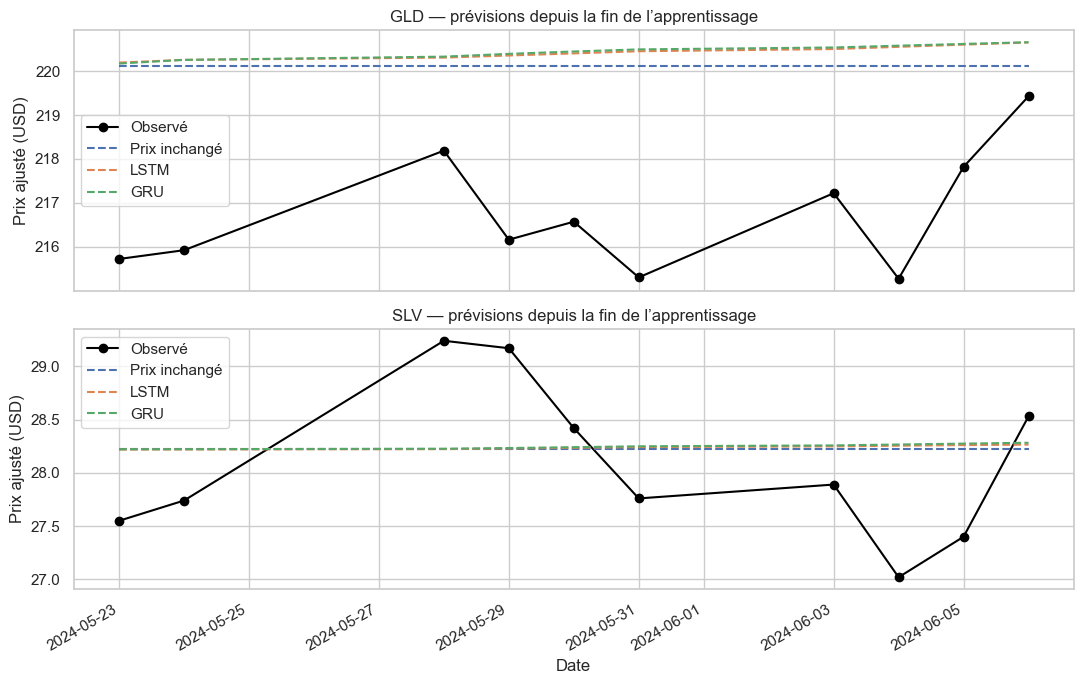

In [44]:
# Prévoir récursivement dix séances depuis la fin de l’apprentissage.
h_max = 10
actifs = ["GLD", "SLV"]
dates_prevision = prix_test.index[:h_max]
dernier_prix = prix_train[actifs].iloc[-1].to_numpy()

previsions_prix_initiales = {
    "Prix inchangé": pd.DataFrame(
        np.tile(dernier_prix, (h_max, 1)),
        index=dates_prevision,
        columns=actifs
    )
}

for nom, modele in modeles_reseaux_finaux.items():
    sequence = valeurs_finales[-fenetre:].copy()
    rendements_predits = []

    for pas in range(h_max):
        prediction_scaled = modele(
            sequence[np.newaxis, :, :],
            training=False
        ).numpy()[0]

        prediction = scaler_final.inverse_transform(
            prediction_scaled.reshape(1, -1)
        )[0]

        rendements_predits.append(prediction)

        # Ajouter la prévision, sans introduire de rendement futur réel.
        sequence = np.vstack([
            sequence[1:],
            prediction_scaled
        ]).astype(np.float32)

    rendements_predits = np.asarray(rendements_predits)

    # Les rendements sont 100 × la différence des log-prix.
    prix_predits = dernier_prix * np.exp(
        np.cumsum(rendements_predits / 100, axis=0)
    )

    previsions_prix_initiales[nom] = pd.DataFrame(
        prix_predits,
        index=dates_prevision,
        columns=actifs
    )

# Mesurer les erreurs sur les cinq et dix premières séances.
resultats_horizons_initiaux = []

for h in [5, 10]:
    reels = prix_test[actifs].iloc[:h].to_numpy()

    for nom, tableau in previsions_prix_initiales.items():
        pred = tableau.iloc[:h].to_numpy()

        for j, symbole in enumerate(actifs):
            erreurs = reels[:, j] - pred[:, j]
            mse = np.mean(erreurs**2)

            resultats_horizons_initiaux.append({
                "Horizon": h,
                "Actif": symbole,
                "Modèle": nom,
                "MSE": mse,
                "RMSE": np.sqrt(mse),
                "MAE": np.mean(np.abs(erreurs)),
                "MAPE (%)": 100 * np.mean(
                    np.abs(erreurs / reels[:, j])
                )
            })

table_horizons_initiaux = pd.DataFrame(
    resultats_horizons_initiaux
)

print(table_horizons_initiaux.round(6).to_string(index=False))

# Comparer les trajectoires prédites aux prix observés.
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for ax, symbole in zip(axes, actifs):
    prix_test[symbole].iloc[:h_max].plot(
        ax=ax, color="black", marker="o", label="Observé"
    )

    for nom, tableau in previsions_prix_initiales.items():
        tableau[symbole].plot(ax=ax, linestyle="--", label=nom)

    ax.set_title(f"{symbole} — prévisions depuis la fin de l’apprentissage")
    ax.set_ylabel("Prix ajusté (USD)")
    ax.legend()

plt.tight_layout()
plt.show()

table_horizons_initiaux.to_csv(
    dossier_prepare / "evaluation_initiale_reseaux_h5_h10.csv",
    index=False
)


In [45]:
import joblib

# Conserver la structure du projet pour retrouver les résultats
# et réutiliser les modèles sans refaire leur entraînement.
dossier_modeles = racine / "models"

for dossier in [dossier_prepare, dossier_figures, dossier_modeles]:
    dossier.mkdir(parents=True, exist_ok=True)

# Sauvegarder les métriques et les trajectoires avec leurs dates.
table_horizons_initiaux.to_csv(
    dossier_prepare / "evaluation_initiale_reseaux_h5_h10.csv",
    index=False
)

trajectoires = pd.concat(
    {
        "Observe": prix_test[actifs].iloc[:h_max],
        **previsions_prix_initiales
    },
    axis=1
)
trajectoires.columns.names = ["Modele", "Actif"]

trajectoires.to_csv(
    dossier_prepare / "previsions_initiales_prix_10_seances.csv",
    index_label="Date",
    date_format="%Y-%m-%d"
)

# Utiliser la figure créée dans la cellule précédente.
fig.savefig(
    dossier_figures / "07_previsions_initiales_reseaux_h10.png",
    dpi=150,
    bbox_inches="tight"
)

# Conserver les réseaux et le scaler associés à leur entraînement.
for nom, modele in modeles_reseaux_finaux.items():
    modele.save(dossier_modeles / f"{nom.lower()}_final.keras")

joblib.dump(
    scaler_final,
    dossier_modeles / "scaler_rendements_final.joblib"
)

# Documenter les réglages nécessaires pour reproduire les prévisions.
pd.DataFrame([
    {
        "Modele": nom,
        "Fenetre": fenetre,
        "Actifs_dans_ordre": "GLD,SLV",
        "Unites": 32,
        "Epoques": epoques_finales[nom],
        "Batch_size": 32,
        "Learning_rate": 0.001,
        "Graine": 42,
        "Fin_apprentissage": str(prix_train.index[-1].date())
    }
    for nom in ["LSTM", "GRU"]
]).to_csv(
    dossier_modeles / "configuration_reseaux_finaux.csv",
    index=False
)

print("Tableaux :", dossier_prepare)
print("Graphiques :", dossier_figures)
print("Modèles :", dossier_modeles)
print("Sauvegardes terminées.")


Tableaux : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\data\processed
Graphiques : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\figures
Modèles : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\models
Sauvegardes terminées.


In [46]:
# Construire des origines communes aux horizons 5 et 10
# pour comparer les méthodes sur les mêmes périodes.
actifs = ["GLD", "SLV"]
horizons = [5, 10]
h_max = max(horizons)

prix_complets = pd.concat([
    prix_train[actifs],
    prix_test[actifs]
])

assert prix_complets.index.is_unique
assert prix_complets.index.is_monotonic_increasing

rendements_complets = (
    100 * np.log(prix_complets).diff()
).dropna()

valeurs_completes = scaler_final.transform(
    rendements_complets
).astype(np.float32)

# Une origine est la dernière séance observée avant la prévision.
# La première origine correspond à la fin de l’apprentissage.
origines = np.arange(
    len(prix_train) - 1,
    len(prix_complets) - h_max
)

# Le rendement associé au prix de position o est à la position o-1.
sequences_origines = np.asarray([
    valeurs_completes[o - fenetre:o]
    for o in origines
], dtype=np.float32)

prix_origines = prix_complets.iloc[origines].to_numpy()
dates_origines = prix_complets.index[origines]

previsions_glissantes = {
    "Prix inchangé": {
        h: prix_origines.copy() for h in horizons
    }
}

# Prévoir dix pas récursifs pour toutes les origines en parallèle.
for nom, modele in modeles_reseaux_finaux.items():
    sequences = sequences_origines.copy()
    prix_predits = prix_origines.copy()
    previsions_glissantes[nom] = {}

    for pas in range(1, h_max + 1):
        pred_scaled = modele.predict(
            sequences, batch_size=128, verbose=0
        )
        pred_rendements = scaler_final.inverse_transform(pred_scaled)

        prix_predits = prix_predits * np.exp(pred_rendements / 100)

        if pas in horizons:
            previsions_glissantes[nom][pas] = prix_predits.copy()

        sequences = np.concatenate([
            sequences[:, 1:, :],
            pred_scaled[:, np.newaxis, :]
        ], axis=1).astype(np.float32)

    print(f"{nom} : prévisions terminées.")

# Conserver une ligne par origine, horizon, actif et méthode.
lignes_predictions = []

for nom, predictions in previsions_glissantes.items():
    for h in horizons:
        reels = prix_complets.iloc[origines + h].to_numpy()
        dates_cibles = prix_complets.index[origines + h]

        for j, symbole in enumerate(actifs):
            lignes_predictions.append(pd.DataFrame({
                "Date origine": dates_origines,
                "Date cible": dates_cibles,
                "Horizon": h,
                "Actif": symbole,
                "Modèle": nom,
                "Réel": reels[:, j],
                "Prévision": predictions[h][:, j]
            }))

predictions_test_reseaux = pd.concat(
    lignes_predictions, ignore_index=True
)

predictions_test_reseaux["Erreur"] = (
    predictions_test_reseaux["Réel"]
    - predictions_test_reseaux["Prévision"]
)

# Calculer les métriques à l’échéance exacte de chaque horizon.
lignes_metriques = []

for (h, actif, nom), groupe in predictions_test_reseaux.groupby(
    ["Horizon", "Actif", "Modèle"]
):
    erreurs = groupe["Erreur"].to_numpy()
    reels = groupe["Réel"].to_numpy()
    mse = np.mean(erreurs**2)

    lignes_metriques.append({
        "Horizon": h,
        "Actif": actif,
        "Modèle": nom,
        "Nombre de prévisions": len(groupe),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": np.mean(np.abs(erreurs)),
        "MAPE (%)": 100 * np.mean(np.abs(erreurs / reels))
    })

table_test_reseaux = pd.DataFrame(lignes_metriques)

predictions_test_reseaux.to_csv(
    dossier_prepare / "predictions_test_glissant_reseaux_h5_h10.csv",
    index=False,
    date_format="%Y-%m-%d"
)
table_test_reseaux.to_csv(
    dossier_prepare / "metriques_test_glissant_reseaux_h5_h10.csv",
    index=False
)

print("\nNombre d’origines communes :", len(origines))
print(table_test_reseaux.round(6).to_string(index=False))
print("\nRésultats sauvegardés.")


LSTM : prévisions terminées.
GRU : prévisions terminées.

Nombre d’origines communes : 394
 Horizon Actif        Modèle  Nombre de prévisions        MSE      RMSE      MAE  MAPE (%)
       5   GLD           GRU                   394  56.282666  7.502177 5.590050  1.888154
       5   GLD          LSTM                   394  56.236275  7.499085 5.582794  1.884266
       5   GLD Prix inchangé                   394  58.073723  7.620612 5.690280  1.921743
       5   SLV           GRU                   394   2.627209  1.620867 1.138581  3.302336
       5   SLV          LSTM                   394   2.660414  1.631078 1.146468  3.313976
       5   SLV Prix inchangé                   394   2.718503  1.648788 1.154518  3.330045
      10   GLD           GRU                   394 108.747041 10.428185 7.741939  2.576002
      10   GLD          LSTM                   394 108.208223 10.402318 7.717277  2.564907
      10   GLD Prix inchangé                   394 114.898008 10.719049 7.998731  2.659021

In [47]:
# Ajouter les modèles classiques aux mêmes origines et horizons.
# Les paramètres restent ceux estimés sur l’apprentissage.
lignes_classiques = []

assert list(var_selectionne.names) == actifs
assert list(var_complementaire.names) == actifs

for nom, resultat_var in [
    ("VAR(0)", var_selectionne),
    ("VAR(1) complémentaire", var_complementaire)
]:
    previsions_var = []

    for o in origines:
        if resultat_var.k_ar == 0:
            rendements_predits = np.tile(
                np.asarray(resultat_var.intercept),
                (h_max, 1)
            )
        else:
            # Utiliser les derniers rendements observés à l’origine.
            historique = rendements_complets.iloc[
                o - resultat_var.k_ar:o
            ][actifs].to_numpy()

            rendements_predits = resultat_var.forecast(
                historique, steps=h_max
            )

        trajectoire = prix_complets.iloc[o][actifs].to_numpy() * np.exp(
            np.cumsum(rendements_predits / 100, axis=0)
        )
        previsions_var.append(trajectoire)

    previsions_var = np.asarray(previsions_var)

    for h in horizons:
        reels = prix_complets.iloc[origines + h][actifs].to_numpy()

        for j, symbole in enumerate(actifs):
            lignes_classiques.append(pd.DataFrame({
                "Date origine": dates_origines,
                "Date cible": prix_complets.index[origines + h],
                "Horizon": h,
                "Actif": symbole,
                "Modèle": nom,
                "Réel": reels[:, j],
                "Prévision": previsions_var[:, h - 1, j]
            }))

# Documenter explicitement l’équivalence de la prévision ARIMA.
predictions_arima = predictions_test_reseaux.loc[
    predictions_test_reseaux["Modèle"] == "Prix inchangé"
].copy()
predictions_arima["Modèle"] = "ARIMA(0,1,0) sans dérive"

predictions_test_comparaison = pd.concat(
    [
        predictions_test_reseaux,
        predictions_arima,
        *lignes_classiques
    ],
    ignore_index=True
)

predictions_test_comparaison["Erreur"] = (
    predictions_test_comparaison["Réel"]
    - predictions_test_comparaison["Prévision"]
)

# Regrouper toutes les métriques de prix dans un tableau commun.
lignes_metriques = []

for (h, actif, nom), groupe in predictions_test_comparaison.groupby(
    ["Horizon", "Actif", "Modèle"]
):
    erreurs = groupe["Erreur"].to_numpy()
    mse = np.mean(erreurs**2)

    lignes_metriques.append({
        "Horizon": h,
        "Actif": actif,
        "Modèle": nom,
        "Nombre de prévisions": len(groupe),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": np.mean(np.abs(erreurs)),
        "MAPE (%)": 100 * np.mean(
            np.abs(erreurs / groupe["Réel"].to_numpy())
        )
    })

table_test_comparaison = pd.DataFrame(lignes_metriques)

predictions_test_comparaison.to_csv(
    dossier_prepare / "predictions_test_comparaison_h5_h10.csv",
    index=False,
    date_format="%Y-%m-%d"
)
table_test_comparaison.to_csv(
    dossier_prepare / "metriques_test_comparaison_h5_h10.csv",
    index=False
)

print(table_test_comparaison.round(6).to_string(index=False))


 Horizon Actif                   Modèle  Nombre de prévisions        MSE      RMSE      MAE  MAPE (%)
       5   GLD ARIMA(0,1,0) sans dérive                   394  58.073723  7.620612 5.690280  1.921743
       5   GLD                      GRU                   394  56.282666  7.502177 5.590050  1.888154
       5   GLD                     LSTM                   394  56.236275  7.499085 5.582794  1.884266
       5   GLD            Prix inchangé                   394  58.073723  7.620612 5.690280  1.921743
       5   GLD                   VAR(0)                   394  56.792769  7.536098 5.608667  1.894892
       5   GLD    VAR(1) complémentaire                   394  56.731044  7.532001 5.607398  1.894363
       5   SLV ARIMA(0,1,0) sans dérive                   394   2.718503  1.648788 1.154518  3.330045
       5   SLV                      GRU                   394   2.627209  1.620867 1.138581  3.302336
       5   SLV                     LSTM                   394   2.660414  1.631078

In [48]:
from scipy.stats import t as student_t
from statsmodels.stats.multitest import multipletests

# Tester l’égalité des erreurs quadratiques moyennes.
# DM négatif signifie que le modèle A a une MSE plus faible.
def test_dm(erreurs_a, erreurs_b, h):
    a = np.asarray(erreurs_a, dtype=float)
    b = np.asarray(erreurs_b, dtype=float)

    assert a.shape == b.shape
    assert np.isfinite(a).all() and np.isfinite(b).all()

    d = a**2 - b**2
    n = len(d)
    moyenne = d.mean()
    centre = d - moyenne

    # Estimateur HAC avec poids de Bartlett.
    # Inclure au moins h-1 retards pour le chevauchement.
    retard = max(h - 1, int(np.floor(4 * (n / 100)**(2 / 9))))
    retard = min(retard, n - 1)

    variance_longue = np.dot(centre, centre) / n

    for k in range(1, retard + 1):
        covariance = np.dot(centre[k:], centre[:-k]) / n
        poids = 1 - k / (retard + 1)
        variance_longue += 2 * poids * covariance

    if variance_longue <= 0:
        return np.nan, np.nan, moyenne, retard

    dm = moyenne / np.sqrt(variance_longue / n)

    # Correction de Harvey–Leybourne–Newbold pour l’horizon h.
    correction = np.sqrt(
        (n + 1 - 2*h + h*(h - 1)/n) / n
    )
    dm *= correction

    p_value = 2 * student_t.sf(abs(dm), df=n - 1)
    return dm, p_value, moyenne, retard


# Comparaisons identiques pour chaque actif et horizon.
# ARIMA et prix inchangé sont équivalents : une seule référence suffit.
paires = [
    ("LSTM", "Prix inchangé"),
    ("GRU", "Prix inchangé"),
    ("VAR(0)", "Prix inchangé"),
    ("LSTM", "VAR(0)"),
    ("GRU", "VAR(0)"),
    ("LSTM", "GRU")
]

resultats_dm = []

for h in horizons:
    for actif in actifs:
        bloc = predictions_test_comparaison.loc[
            (predictions_test_comparaison["Horizon"] == h)
            & (predictions_test_comparaison["Actif"] == actif)
        ]

        # Aligner les erreurs par origine et cible avant comparaison.
        erreurs = bloc.pivot(
            index=["Date origine", "Date cible"],
            columns="Modèle",
            values="Erreur"
        ).sort_index()

        for modele_a, modele_b in paires:
            paire = erreurs[[modele_a, modele_b]].dropna()

            dm, p, difference, retard = test_dm(
                paire[modele_a],
                paire[modele_b],
                h
            )

            resultats_dm.append({
                "Horizon": h,
                "Actif": actif,
                "Modèle A": modele_a,
                "Modèle B": modele_b,
                "N": len(paire),
                "Retards HAC": retard,
                "MSE A - MSE B": difference,
                "DM corrigé": dm,
                "p-value": p
            })

table_dm = pd.DataFrame(resultats_dm)

# Corriger l’ensemble des comparaisons affichées.
valides = table_dm["p-value"].notna()
table_dm["p-value Holm"] = np.nan
table_dm.loc[valides, "p-value Holm"] = multipletests(
    table_dm.loc[valides, "p-value"],
    method="holm"
)[1]

table_dm["Significatif à 5 % (Holm)"] = (
    table_dm["p-value Holm"] < 0.05
)

table_dm.to_csv(
    dossier_prepare / "tests_dm_h5_h10.csv",
    index=False
)

print(table_dm.round(6).to_string(index=False))


 Horizon Actif Modèle A      Modèle B   N  Retards HAC  MSE A - MSE B  DM corrigé  p-value  p-value Holm  Significatif à 5 % (Holm)
       5   GLD     LSTM Prix inchangé 394            5      -1.837449   -3.059577 0.002368      0.052106                      False
       5   GLD      GRU Prix inchangé 394            5      -1.791057   -1.835174 0.067236      0.941298                      False
       5   GLD   VAR(0) Prix inchangé 394            5      -1.280954   -3.007370 0.002805      0.058896                      False
       5   GLD     LSTM        VAR(0) 394            5      -0.556494   -1.431445 0.153097      1.000000                      False
       5   GLD      GRU        VAR(0) 394            5      -0.510103   -0.828003 0.408171      1.000000                      False
       5   GLD     LSTM           GRU 394            5      -0.046392   -0.084547 0.932664      1.000000                      False
       5   SLV     LSTM Prix inchangé 394            5      -0.058089   -1.9

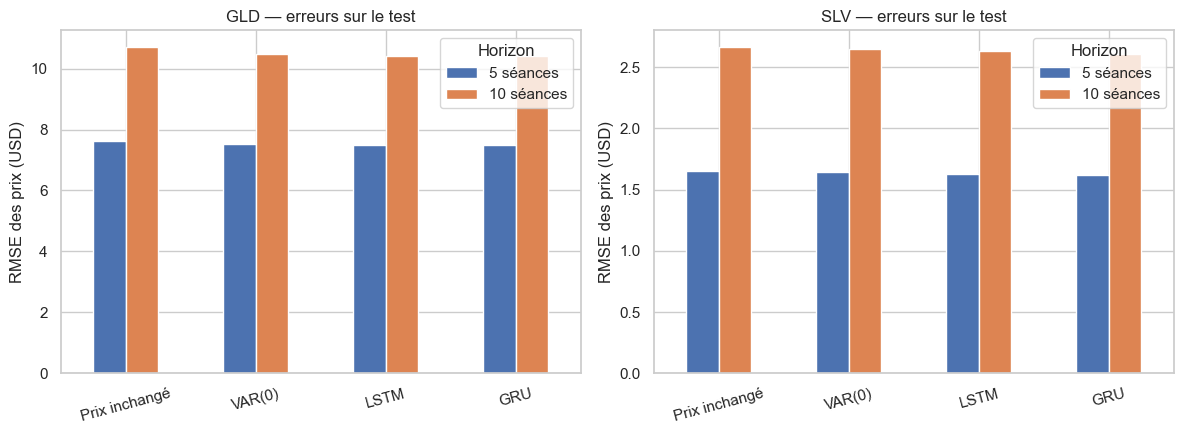

Graphique de comparaison sauvegardé.


In [49]:
# Comparer les RMSE dans des panneaux séparés par actif,
# car les niveaux de prix de GLD et SLV diffèrent.
ordre_modeles = ["Prix inchangé", "VAR(0)", "LSTM", "GRU"]

fig_comparaison, axes = plt.subplots(
    1, 2, figsize=(12, 4.5)
)

for ax, actif in zip(axes, actifs):
    tableau = (
        table_test_comparaison.loc[
            (table_test_comparaison["Actif"] == actif)
            & table_test_comparaison["Modèle"].isin(ordre_modeles)
        ]
        .pivot(index="Modèle", columns="Horizon", values="RMSE")
        .reindex(ordre_modeles)
    )

    tableau.columns = [
        f"{h} séances" for h in tableau.columns
    ]
    tableau.plot.bar(ax=ax, rot=15)

    ax.set_title(f"{actif} — erreurs sur le test")
    ax.set_ylabel("RMSE des prix (USD)")
    ax.set_xlabel("")
    ax.legend(title="Horizon")

fig_comparaison.tight_layout()
fig_comparaison.savefig(
    dossier_figures / "08_comparaison_rmse_test_h5_h10.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print("Graphique de comparaison sauvegardé.")


### Conclusion de la comparaison prédictive

Sur les 394 origines du test, le LSTM obtient les meilleures
erreurs pour GLD et le GRU pour SLV aux horizons 5 et 10 séances.

Après correction de Holm des 24 comparaisons, seules les
améliorations de GLD à 10 séances restent significatives :
LSTM contre prix inchangé (p ajustée = 0,0067) et VAR(0)
contre prix inchangé (p ajustée = 0,0185).

Aucune différence significative n’est détectée entre LSTM
et VAR(0), ni entre LSTM et GRU. Pour SLV, les gains observés
ne sont pas significatifs après correction.

Le VAR(0) constitue donc un compromis intéressant entre
performance, simplicité et coût de calcul. Le LSTM conserve
la meilleure performance numérique pour GLD, sans supériorité
statistique établie face au VAR(0).


### Intervalles GARCH et couverture

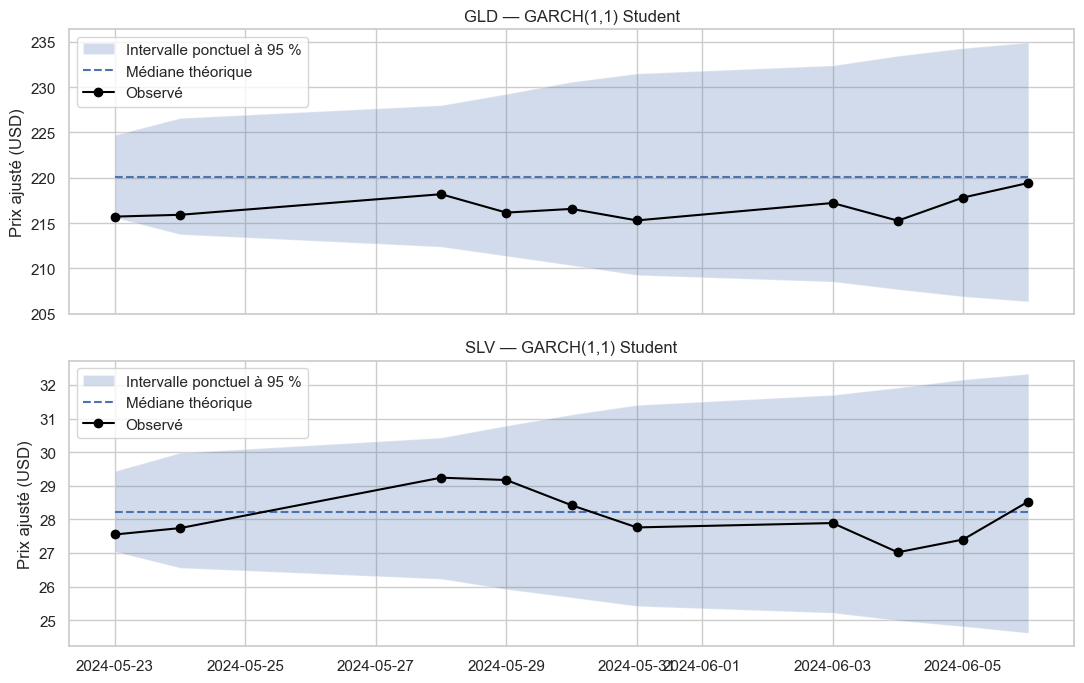

      Date Actif  Horizon  Mediane theorique  Borne basse 95 %  Borne haute 95 %  Prix observe  Dans intervalle
2024-05-30   GLD        5             220.11          210.3468          230.5923        216.57             True
2024-06-06   GLD       10             220.11          206.3589          234.9386        219.43             True
2024-05-30   SLV        5              28.22           25.6745           31.1214         28.42             True
2024-06-06   SLV       10              28.22           24.6233           32.3323         28.53             True


In [50]:
# Simuler des trajectoires GARCH sans utiliser les observations du test.
# Les intervalles sont ponctuels et conditionnels aux paramètres estimés.
n_simulations = 20000
h_garch = 10
dates_garch = prix_test.index[:h_garch]

intervalles_garch = []

for j, symbole in enumerate(["GLD", "SLV"]):
    resultat = modeles_garch[symbole]
    params = resultat.params

    omega = float(params["omega"])
    alpha = float(params["alpha[1]"])
    beta = float(params["beta[1]"])
    nu = float(params["nu"])

    assert nu > 2, "La Student doit avoir une variance finie."

    rng = np.random.default_rng(42 + j)

    # Initialiser depuis le dernier rendement et la dernière variance
    # conditionnelle de la période d’apprentissage.
    dernier_residu = float(resultat.resid.iloc[-1])
    derniere_variance = float(
        resultat.conditional_volatility.iloc[-1] ** 2
    )

    variance = np.full(
        n_simulations,
        omega + alpha * dernier_residu**2
        + beta * derniere_variance
    )

    variations_log = np.zeros(n_simulations)
    prix_depart = float(prix_train[symbole].iloc[-1])

    for pas in range(1, h_garch + 1):
        # Standardiser la Student pour obtenir une variance égale à 1.
        z = rng.standard_t(nu, size=n_simulations)
        z *= np.sqrt((nu - 2) / nu)

        residus_simules = np.sqrt(variance) * z
        variations_log += residus_simules / 100

        # Transformer les quantiles des log-prix en quantiles des prix.
        q_bas, q_haut = np.quantile(
            variations_log, [0.025, 0.975]
        )

        intervalles_garch.append({
            "Date": dates_garch[pas - 1],
            "Actif": symbole,
            "Horizon": pas,
            "Mediane theorique": prix_depart,
            "Borne basse 95 %": prix_depart * np.exp(q_bas),
            "Borne haute 95 %": prix_depart * np.exp(q_haut),
            "Prix observe": float(
                prix_test[symbole].iloc[pas - 1]
            )
        })

        variance = (
            omega + alpha * residus_simules**2
            + beta * variance
        )

table_intervalles_garch = pd.DataFrame(intervalles_garch)

table_intervalles_garch["Dans intervalle"] = (
    (table_intervalles_garch["Prix observe"]
     >= table_intervalles_garch["Borne basse 95 %"])
    & (table_intervalles_garch["Prix observe"]
       <= table_intervalles_garch["Borne haute 95 %"])
)

# Sauvegarder les bornes et les observations correspondantes.
table_intervalles_garch.to_csv(
    dossier_prepare / "intervalles_garch_initiaux_h10.csv",
    index=False,
    date_format="%Y-%m-%d"
)

fig_garch, axes = plt.subplots(
    2, 1, figsize=(11, 7), sharex=True
)

for ax, symbole in zip(axes, ["GLD", "SLV"]):
    bloc = table_intervalles_garch.loc[
        table_intervalles_garch["Actif"] == symbole
    ]

    ax.fill_between(
        bloc["Date"],
        bloc["Borne basse 95 %"].to_numpy(),
        bloc["Borne haute 95 %"].to_numpy(),
        alpha=0.25,
        label="Intervalle ponctuel à 95 %"
    )
    ax.plot(
        bloc["Date"], bloc["Mediane theorique"],
        linestyle="--", label="Médiane théorique"
    )
    ax.plot(
        bloc["Date"], bloc["Prix observe"],
        color="black", marker="o", label="Observé"
    )

    ax.set_title(f"{symbole} — GARCH(1,1) Student")
    ax.set_ylabel("Prix ajusté (USD)")
    ax.legend()

fig_garch.tight_layout()
fig_garch.savefig(
    dossier_figures / "09_intervalles_garch_initiaux_h10.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print(
    table_intervalles_garch.loc[
        table_intervalles_garch["Horizon"].isin([5, 10])
    ].round(4).to_string(index=False)
)


In [51]:
# Évaluer les intervalles avec des paramètres fixes et une variance
# actualisée uniquement à partir des observations disponibles.
n_simulations_glissantes = 10000
lignes_intervalles = []

for j, symbole in enumerate(actifs):
    resultat = modeles_garch[symbole]
    params = resultat.params

    omega = float(params["omega"])
    alpha = float(params["alpha[1]"])
    beta = float(params["beta[1]"])
    nu = float(params["nu"])

    rng = np.random.default_rng(100 + j)

    # La première origine est la dernière séance d’apprentissage.
    variance_origine = float(
        resultat.conditional_volatility.iloc[-1] ** 2
    )

    for numero, o in enumerate(origines):
        if numero > 0:
            # Variance de la séance courante, calculée avec
            # le rendement de la séance précédente.
            rendement_precedent = float(
                rendements_complets[symbole].iloc[o - 2]
            )
            variance_origine = (
                omega + alpha * rendement_precedent**2
                + beta * variance_origine
            )

        rendement_origine = float(
            rendements_complets[symbole].iloc[o - 1]
        )

        variance_simulee = np.full(
            n_simulations_glissantes,
            omega + alpha * rendement_origine**2
            + beta * variance_origine
        )
        cumul_log = np.zeros(n_simulations_glissantes)
        prix_depart = float(prix_complets[symbole].iloc[o])

        for pas in range(1, h_max + 1):
            z = rng.standard_t(nu, size=n_simulations_glissantes)
            z *= np.sqrt((nu - 2) / nu)

            choc = np.sqrt(variance_simulee) * z
            cumul_log += choc / 100

            if pas in horizons:
                q_bas, q_haut = np.quantile(
                    cumul_log, [0.025, 0.975]
                )

                lignes_intervalles.append({
                    "Date origine": prix_complets.index[o],
                    "Date cible": prix_complets.index[o + pas],
                    "Actif": symbole,
                    "Horizon": pas,
                    "Borne basse": prix_depart * np.exp(q_bas),
                    "Borne haute": prix_depart * np.exp(q_haut),
                    "Observe": float(
                        prix_complets[symbole].iloc[o + pas]
                    )
                })

            variance_simulee = (
                omega + alpha * choc**2
                + beta * variance_simulee
            )

    print(f"{symbole} : intervalles terminés.", flush=True)

intervalles_test_garch = pd.DataFrame(lignes_intervalles)

bas = intervalles_test_garch["Borne basse"]
haut = intervalles_test_garch["Borne haute"]
observe = intervalles_test_garch["Observe"]

intervalles_test_garch["Couvert"] = (
    (observe >= bas) & (observe <= haut)
)
intervalles_test_garch["Largeur"] = haut - bas

# Le score pénalise à la fois la largeur et les dépassements.
# Une valeur plus faible est préférable, à actif identique.
intervalles_test_garch["Score intervalle"] = (
    haut - bas
    + (2 / 0.05) * np.maximum(bas - observe, 0)
    + (2 / 0.05) * np.maximum(observe - haut, 0)
)

bilan_intervalles_garch = (
    intervalles_test_garch.groupby(["Actif", "Horizon"])
    .agg(
        N=("Couvert", "size"),
        Couverture_pct=("Couvert", lambda x: 100 * x.mean()),
        Largeur_moyenne_USD=("Largeur", "mean"),
        Score_moyen=("Score intervalle", "mean")
    )
    .reset_index()
)

intervalles_test_garch.to_csv(
    dossier_prepare / "intervalles_garch_test_glissant.csv",
    index=False,
    date_format="%Y-%m-%d"
)
bilan_intervalles_garch.to_csv(
    dossier_prepare / "bilan_intervalles_garch_test.csv",
    index=False
)

print(bilan_intervalles_garch.round(4).to_string(index=False))


GLD : intervalles terminés.
SLV : intervalles terminés.
Actif  Horizon   N  Couverture_pct  Largeur_moyenne_USD  Score_moyen
  GLD        5 394         93.9086              28.1321      38.3057
  GLD       10 394         92.1320              39.7148      58.5353
  SLV        5 394         93.6548               5.4870       7.6144
  SLV       10 394         93.4010               7.7835      10.2039


### Évaluation des intervalles GARCH

Sur 394 origines, les intervalles nominaux à 95 % couvrent
93,91 % et 92,13 % des prix de GLD aux horizons 5 et 10 séances,
contre 93,65 % et 93,40 % pour SLV.

Une sous-couverture descriptive apparaît, particulièrement
pour GLD à 10 séances. La largeur moyenne augmente avec l’horizon,
ce qui traduit une incertitude plus importante.

Ces intervalles restent approximatifs : les paramètres sont fixes,
leur incertitude d’estimation est ignorée et des effets ARCH
résiduels persistent. Le chevauchement des horizons empêche
d’interpréter les 394 observations comme indépendantes.


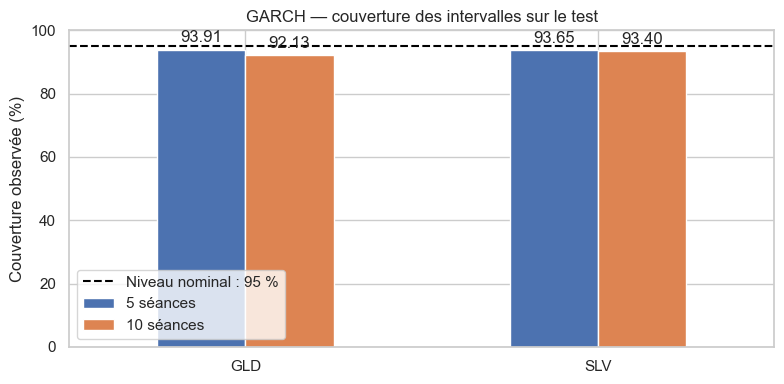

In [52]:
# Visualiser l’écart entre la couverture observée et les 95 % visés.
table_couverture = bilan_intervalles_garch.pivot(
    index="Actif",
    columns="Horizon",
    values="Couverture_pct"
)
table_couverture.columns = [
    f"{h} séances" for h in table_couverture.columns
]

ax = table_couverture.plot.bar(
    figsize=(8, 4), rot=0, ylim=(0, 100)
)
ax.axhline(
    95, color="black", linestyle="--", label="Niveau nominal : 95 %"
)
ax.set_ylabel("Couverture observée (%)")
ax.set_xlabel("")
ax.set_title("GARCH — couverture des intervalles sur le test")
ax.legend()

for conteneur in ax.containers:
    ax.bar_label(conteneur, fmt="%.2f", padding=3)

fig_couverture = ax.get_figure()
fig_couverture.tight_layout()
fig_couverture.savefig(
    dossier_figures / "10_couverture_intervalles_garch_test.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


### Intervalles des modèles classiques

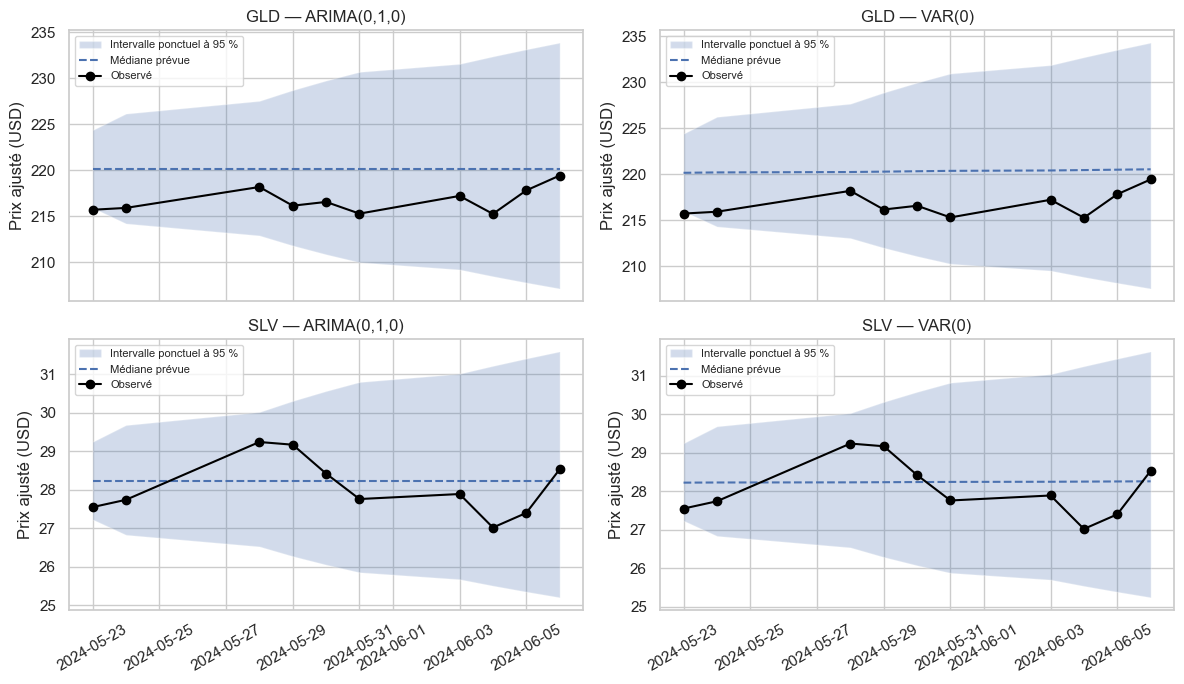

      Date Actif       Modèle  Horizon  Mediane prix  Borne basse  Borne haute  Observe
2024-05-30   GLD ARIMA(0,1,0)        5      220.1100     210.8826     229.7412   216.57
2024-05-30   GLD       VAR(0)        5      220.3215     211.0845     229.9628   216.57
2024-06-06   GLD ARIMA(0,1,0)       10      220.1100     207.1747     233.8530   219.43
2024-06-06   GLD       VAR(0)       10      220.5333     207.5720     234.3039   219.43
2024-05-30   SLV ARIMA(0,1,0)        5       28.2200      26.0561      30.5636    28.42
2024-05-30   SLV       VAR(0)        5       28.2392      26.0733      30.5851    28.42
2024-06-06   SLV ARIMA(0,1,0)       10       28.2200      25.2091      31.5905    28.53
2024-06-06   SLV       VAR(0)       10       28.2585      25.2428      31.6345    28.53


In [53]:
from scipy.stats import norm

# Construire des intervalles ponctuels à 95 % sous les hypothèses
# gaussiennes et de variance constante des modèles classiques.
h_classique = 10
dates_classiques = prix_test.index[:h_classique]
lignes_intervalles_classiques = []
z_975 = norm.ppf(0.975)

for j, symbole in enumerate(["GLD", "SLV"]):
    # ARIMA : prévoir les log-prix puis transformer les bornes.
    prevision = modeles_retenus[symbole].get_forecast(
        steps=h_classique
    )
    centre_log = np.asarray(prevision.predicted_mean)
    bornes_log = np.asarray(prevision.conf_int(alpha=0.05))

    # VAR(0) : cumuler les rendements moyens.
    # Sous l’hypothèse de chocs non autocorrélés, la variance
    # du rendement cumulé à h séances vaut h fois la variance.
    moyenne_rendement = float(var_selectionne.intercept[j])
    covariance = np.asarray(var_selectionne.sigma_u)
    variance_rendement = float(covariance[j, j])
    log_depart = np.log(float(prix_train[symbole].iloc[-1]))

    for pas in range(1, h_classique + 1):
        lignes_intervalles_classiques.append({
            "Date": dates_classiques[pas - 1],
            "Actif": symbole,
            "Modèle": "ARIMA(0,1,0)",
            "Horizon": pas,
            "Mediane prix": np.exp(centre_log[pas - 1]),
            "Borne basse": np.exp(bornes_log[pas - 1, 0]),
            "Borne haute": np.exp(bornes_log[pas - 1, 1]),
            "Observe": float(prix_test[symbole].iloc[pas - 1])
        })

        centre_var = log_depart + pas * moyenne_rendement / 100
        ecart_var = np.sqrt(pas * variance_rendement) / 100

        lignes_intervalles_classiques.append({
            "Date": dates_classiques[pas - 1],
            "Actif": symbole,
            "Modèle": "VAR(0)",
            "Horizon": pas,
            "Mediane prix": np.exp(centre_var),
            "Borne basse": np.exp(centre_var - z_975 * ecart_var),
            "Borne haute": np.exp(centre_var + z_975 * ecart_var),
            "Observe": float(prix_test[symbole].iloc[pas - 1])
        })

intervalles_classiques = pd.DataFrame(
    lignes_intervalles_classiques
)

intervalles_classiques.to_csv(
    dossier_prepare / "intervalles_classiques_initiaux_h10.csv",
    index=False,
    date_format="%Y-%m-%d"
)

fig_classiques, axes = plt.subplots(
    2, 2, figsize=(12, 7), sharex=True
)

for i, symbole in enumerate(["GLD", "SLV"]):
    for j, nom in enumerate(["ARIMA(0,1,0)", "VAR(0)"]):
        ax = axes[i, j]
        bloc = intervalles_classiques.loc[
            (intervalles_classiques["Actif"] == symbole)
            & (intervalles_classiques["Modèle"] == nom)
        ]

        ax.fill_between(
            bloc["Date"],
            bloc["Borne basse"].to_numpy(),
            bloc["Borne haute"].to_numpy(),
            alpha=0.25,
            label="Intervalle ponctuel à 95 %"
        )
        ax.plot(
            bloc["Date"], bloc["Mediane prix"],
            linestyle="--", label="Médiane prévue"
        )
        ax.plot(
            bloc["Date"], bloc["Observe"],
            color="black", marker="o", label="Observé"
        )
        ax.set_title(f"{symbole} — {nom}")
        ax.set_ylabel("Prix ajusté (USD)")
        ax.tick_params(axis="x", rotation=30)
        ax.legend(fontsize=8)

fig_classiques.tight_layout()
fig_classiques.savefig(
    dossier_figures / "12_intervalles_classiques_initiaux_h10.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

print(
    intervalles_classiques.loc[
        intervalles_classiques["Horizon"].isin([5, 10])
    ].round(4).to_string(index=False)
)


## 9. IA générative : consultations et analyse critique

Les consultations et critiques sont assistées par IA et rétrospectives. Les réponses intégrales sont conservées dans `reports/llm`. Ces fichiers annexes doivent accompagner le notebook.


In [54]:
# Documenter la synthèse et l’assistance reçue sans présenter
# ce texte comme une interprétation indépendante antérieure au LLM.
dossier_llm = racine / "reports" / "llm"
dossier_llm.mkdir(parents=True, exist_ok=True)

synthese = """
Synthèse des résultats

Pour GLD, le LSTM obtient les meilleures erreurs sur le test aux
horizons 5 et 10 séances. À 10 séances, son amélioration face au prix
inchangé est significative après correction de Holm (p = 0,0067).
Cependant, sa supériorité face au VAR(0) n’est pas significative.
Le VAR(0) constitue donc un compromis intéressant entre précision,
simplicité et coût de calcul.

Pour SLV, le GRU obtient les meilleures erreurs sur le test, mais
les comparaisons réalisées ne montrent pas de différence significative
après correction de Holm. Les gains observés doivent rester prudents,
d’autant que la validation temporelle ne montrait pas d’avantage régulier
des réseaux.

Les intervalles GARCH nominaux à 95 % présentent des couvertures
observées comprises entre 92,13 % et 93,91 %. Cela suggère une
sous-couverture sur la période test, sans constituer à lui seul
un test formel de mauvaise calibration. Les paramètres sont fixes,
leur incertitude d’estimation est ignorée et des effets ARCH résiduels
persistent.

Ces résultats ne démontrent pas la rentabilité d’une stratégie
d’investissement : aucune stratégie avec frais de transaction,
contraintes d’exécution et mesure du risque n’a été évaluée.
Les performances peuvent également varier sur d’autres périodes.

Note méthodologique :
Cette synthèse a été rédigée avec l’aide de ChatGPT après l’analyse
des résultats. Elle ne constitue pas une interprétation personnelle
rédigée avant toute consultation d’un LLM.
""".strip()

fichier = dossier_llm / "01_synthese.txt"

# Préserver les versions précédentes lors d’une nouvelle exécution.
if fichier.exists():
    numero = 2
    while (
        dossier_llm / f"01_synthese{numero}.txt"
    ).exists():
        numero += 1

    fichier = dossier_llm / f"01_synthese{numero}.txt"

fichier.write_text(synthese + "\n", encoding="utf-8")

print(synthese)
print("\nSauvegarde :", fichier)


Synthèse des résultats

Pour GLD, le LSTM obtient les meilleures erreurs sur le test aux
horizons 5 et 10 séances. À 10 séances, son amélioration face au prix
inchangé est significative après correction de Holm (p = 0,0067).
Cependant, sa supériorité face au VAR(0) n’est pas significative.
Le VAR(0) constitue donc un compromis intéressant entre précision,
simplicité et coût de calcul.

Pour SLV, le GRU obtient les meilleures erreurs sur le test, mais
les comparaisons réalisées ne montrent pas de différence significative
après correction de Holm. Les gains observés doivent rester prudents,
d’autant que la validation temporelle ne montrait pas d’avantage régulier
des réseaux.

Les intervalles GARCH nominaux à 95 % présentent des couvertures
observées comprises entre 92,13 % et 93,91 %. Cela suggère une
sous-couverture sur la période test, sans constituer à lui seul
un test formel de mauvaise calibration. Les paramètres sont fixes,
leur incertitude d’estimation est ignorée et des effets A

In [55]:
# Préparer une consultation fondée uniquement sur les statistiques
# d’apprentissage et conserver le prompt intégral dans reports/llm.
dossier_llm = racine / "reports" / "llm"
dossier_llm.mkdir(parents=True, exist_ok=True)

prompt_hypotheses = f"""
Je réalise un projet de séries temporelles sur GLD et SLV,
deux instruments donnant une exposition à l’or et à l’argent.

Les observations sont quotidiennes, par séance boursière.
L’historique couvre 2010–2025 et les derniers 10 % sont réservés
au test. Les tableaux ci-dessous concernent uniquement
la période d’apprentissage.

Les rendements sont calculés comme :
100 × différence du logarithme des prix ajustés.
La kurtosis présentée est un excès de kurtosis.

STATISTIQUES DES RENDEMENTS
{statistiques.to_string()}

TESTS DE STATIONNARITÉ
{tests_stationnarite.to_string(index=False)}

À partir de ces informations :
1. Propose des hypothèses de modèles de moyenne et de volatilité
   à tester, en justifiant chaque proposition.
2. Précise les diagnostics supplémentaires nécessaires avant
   de retenir ARIMA, SARIMA, VAR, VECM ou GARCH.
3. Explique comment comparer LSTM et GRU aux modèles classiques
   sans fuite d’information.
4. Distingue les conclusions soutenues par les tableaux des
   hypothèses qui restent à vérifier.

N’invente aucun résultat, aucune p-value ni aucune causalité.
Ne suppose pas une saisonnalité ou une cointégration non testée.
Ne formule pas de recommandation d’investissement à cette étape.
""".strip()

fichier_prompt = dossier_llm / "02_prompt_hypotheses.txt"

if fichier_prompt.exists():
    print("Prompt déjà enregistré ; fichier conservé.")
else:
    fichier_prompt.write_text(
        prompt_hypotheses + "\n",
        encoding="utf-8"
    )
    print("Prompt sauvegardé :", fichier_prompt)

print("\n" + prompt_hypotheses)


Prompt déjà enregistré ; fichier conservé.

Je réalise un projet de séries temporelles sur GLD et SLV,
deux instruments donnant une exposition à l’or et à l’argent.

Les observations sont quotidiennes, par séance boursière.
L’historique couvre 2010–2025 et les derniers 10 % sont réservés
au test. Les tableaux ci-dessous concernent uniquement
la période d’apprentissage.

Les rendements sont calculés comme :
100 × différence du logarithme des prix ajustés.
La kurtosis présentée est un excès de kurtosis.

STATISTIQUES DES RENDEMENTS
     Moyenne (%)  Écart-type (%)  Variance  Minimum (%)  Maximum (%)  Asymétrie  Excès de kurtosis
GLD     0.019212        0.977263  0.955044    -9.190507     4.787391  -0.501465           4.995916
SLV     0.013629        1.820814  3.315364   -15.252920     8.748747  -0.716639           7.079888

TESTS DE STATIONNARITÉ
Actif     Série Spécification  ADF statistique  ADF p-value  ADF retards  KPSS statistique  KPSS p-value  KPSS retards
  GLD  Log-prix         

In [56]:
# Vérifier que la réponse intégrale est archivée avant son analyse.
fichier_reponse = dossier_llm / "03_reponse_hypotheses.md"

if not fichier_reponse.exists():
    raise FileNotFoundError(
        "Crée reports/llm/03_reponse_hypotheses.md "
        "et colle la réponse complète du LLM."
    )

reponse_hypotheses = fichier_reponse.read_text(encoding="utf-8")
assert reponse_hypotheses.strip(), "Le fichier est vide."

# Documenter le contexte réel de cette consultation.
contexte = """
Consultation rétrospective effectuée dans la conversation de travail
ChatGPT le 9 octobre 2026, après l’estimation des modèles.
Le LLM avait accès aux échanges précédents : cette réponse ne constitue
pas une consultation indépendante limitée aux tableaux du prompt.
""".strip()

(dossier_llm / "03_contexte_consultation.txt").write_text(
    contexte + "\n", encoding="utf-8"
)

# Comparer les propositions du LLM aux résultats effectivement obtenus.
critique_hypotheses = pd.DataFrame([
    {
        "Point": "Stationnarité",
        "Évaluation": "Cohérent",
        "Justification":
            "Les tests soutiennent des log-prix I(1) et des rendements "
            "stationnaires ; la réponse conserve une formulation prudente."
    },
    {
        "Point": "Modèle de moyenne",
        "Évaluation": "Confirmé par les estimations",
        "Justification":
            "ARIMA(0,1,0) sans dérive est retenu par les comparaisons "
            "manuelle et automatique."
    },
    {
        "Point": "Volatilité",
        "Évaluation": "Pertinent mais validation partielle",
        "Justification":
            "ARCH-LM motive GARCH. La Student est pertinente comme candidate, "
            "mais des effets ARCH résiduels subsistent après estimation."
    },
    {
        "Point": "Cointégration et saisonnalité",
        "Évaluation": "Prudence appropriée",
        "Justification":
            "La réponse ne les déduit pas des statistiques descriptives "
            "et exige des diagnostics supplémentaires."
    },
    {
        "Point": "Réseaux récurrents",
        "Évaluation": "Protocole pertinent",
        "Justification":
            "La réponse recommande une validation temporelle, un scaler "
            "ajusté sur le passé et une référence naïve."
    },
    {
        "Point": "Limites de la réponse",
        "Évaluation": "À compléter",
        "Justification":
            "La réponse propose des familles de modèles sans fixer leurs "
            "ordres. Une Student symétrique ne décrit pas à elle seule "
            "l’asymétrie empirique des rendements."
    }
])

critique_hypotheses.to_csv(
    dossier_llm / "04_critique_hypotheses_assistee.csv",
    index=False
)

display(critique_hypotheses)
print("Réponse, contexte et grille de critique sauvegardés.")


,Point,Évaluation,Justification
0,Stationnarité,Cohérent,Les tests soutiennent des log-prix I(1) et des...
1,Modèle de moyenne,Confirmé par les estimations,"ARIMA(0,1,0) sans dérive est retenu par les co..."
2,Volatilité,Pertinent mais validation partielle,ARCH-LM motive GARCH. La Student est pertinent...
3,Cointégration et saisonnalité,Prudence appropriée,La réponse ne les déduit pas des statistiques ...
4,Réseaux récurrents,Protocole pertinent,La réponse recommande une validation temporell...
5,Limites de la réponse,À compléter,La réponse propose des familles de modèles san...


Réponse, contexte et grille de critique sauvegardés.


In [57]:
# Fournir les résultats exacts pour une explication vulgarisée,
# puis conserver le prompt intégral pour les annexes.
prompt_vulgarisation = f"""
Explique les résultats de mon étude GLD/SLV à un décideur
non statisticien, en français, en 400 à 600 mots.

PROTOCOLE
Les modèles sont estimés sur les premiers 90 % de l’historique.
LSTM et GRU ont été évalués par validation croisée temporelle.
Sur le test final, les prévisions utilisent 394 origines communes,
aux horizons de 5 et 10 séances. Les paramètres restent fixes,
mais les observations disponibles sont actualisées à chaque origine.

Les métriques ci-dessous portent sur les prix à l’échéance exacte.
ARIMA(0,1,0) sans dérive et prix inchangé donnent les mêmes prévisions.

MÉTRIQUES SUR LE TEST
{table_test_comparaison.to_string(index=False)}

TESTS DE DIEBOLD–MARIANO
La perte comparée est l’erreur quadratique.
La variance est estimée par HAC ; la correction de Holm
porte sur les 24 comparaisons.
{table_dm.to_string(index=False)}

INTERVALLES GARCH
Intervalles ponctuels nominaux à 95 %, simulés avec innovations
de Student. Les paramètres sont fixes et leur incertitude
d’estimation n’est pas intégrée.
{bilan_intervalles_garch.to_string(index=False)}

LIMITES CONNUES
La validation temporelle ne montre pas un avantage régulier
des réseaux face au rendement nul.
Des effets ARCH résiduels persistent après estimation GARCH,
particulièrement pour SLV.
Aucune stratégie de trading ni rentabilité après frais n’a été testée.

CONSIGNES
- Explique les rôles différents de la prévision du prix et de GARCH.
- Distingue meilleur score numérique et différence significative.
- Compare précision, simplicité et coût de calcul sans inventer
  de mesures de temps.
- Explique les couvertures observées sans affirmer qu’un test
  formel de calibration a été réalisé.
- Une différence non significative ne prouve pas l’équivalence.
- N’invente aucune valeur ni causalité.
- Ne donne pas encore de recommandation d’investissement.
""".strip()

fichier_prompt = dossier_llm / "05_prompt_vulgarisation.txt"

if not fichier_prompt.exists():
    fichier_prompt.write_text(prompt_vulgarisation + "\n", encoding="utf-8")
else:
    print("Prompt existant conservé.")

print("Prompt sauvegardé :", fichier_prompt)


Prompt existant conservé.
Prompt sauvegardé : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\reports\llm\05_prompt_vulgarisation.txt


In [58]:
# Archiver et vérifier l’explication destinée au décideur.
fichier = dossier_llm / "06_reponse_vulgarisation.md"

if not fichier.exists():
    raise FileNotFoundError(
        "Crée reports/llm/06_reponse_vulgarisation.md "
        "et colle la réponse complète."
    )

assert fichier.read_text(encoding="utf-8").strip(), "Le fichier est vide."

critique_vulgarisation = pd.DataFrame([
    {
        "Point": "Classement numérique",
        "Analyse":
            "La réponse identifie correctement le LSTM pour GLD "
            "et le GRU pour SLV sur le test."
    },
    {
        "Point": "Significativité",
        "Analyse":
            "Elle distingue les gains numériques des deux différences "
            "significatives après Holm, pour GLD à 10 séances."
    },
    {
        "Point": "Intervalles GARCH",
        "Analyse":
            "Elle décrit une sous-couverture observée sans prétendre "
            "qu’un test formel de calibration a été effectué."
    },
    {
        "Point": "Limites",
        "Analyse":
            "Elle rappelle l’instabilité des gains en validation "
            "et l’absence d’évaluation de rentabilité après frais."
    },
    {
        "Point": "Éléments à compléter",
        "Analyse":
            "Elle ne précise pas que les 394 origines se chevauchent "
            "et ne sont pas indépendantes. Les tests DM utilisent "
            "une correction HAC pour cette dépendance."
    }
])

critique_vulgarisation.to_csv(
    dossier_llm / "07_critique_vulgarisation_assistee.csv",
    index=False
)

display(critique_vulgarisation)
print("Vulgarisation et critique assistée sauvegardées.")


,Point,Analyse
0,Classement numérique,La réponse identifie correctement le LSTM pour...
1,Significativité,Elle distingue les gains numériques des deux d...
2,Intervalles GARCH,Elle décrit une sous-couverture observée sans ...
3,Limites,Elle rappelle l’instabilité des gains en valid...
4,Éléments à compléter,Elle ne précise pas que les 394 origines se ch...


Vulgarisation et critique assistée sauvegardées.


In [59]:
# Fournir les prévisions à la première origine du test sans révéler
# les prix futurs observés au LLM.
date_decision = prix_train.index[-1]
lignes_scenario = []

for nom, tableau in previsions_prix_initiales.items():
    for h in [5, 10]:
        for actif in actifs:
            prix_depart = float(prix_train[actif].iloc[-1])
            prix_prevu = float(tableau[actif].iloc[h - 1])

            lignes_scenario.append({
                "Modèle": nom,
                "Actif": actif,
                "Horizon": h,
                "Dernier prix": prix_depart,
                "Prix prévu": prix_prevu,
                "Variation prévue (%)":
                    100 * (prix_prevu / prix_depart - 1)
            })

scenario_recommandations = pd.DataFrame(lignes_scenario)

# Les bornes GARCH proviennent également de cette origine.
# Ne pas transmettre les observations futures ni leur couverture.
bornes_scenario = table_intervalles_garch.loc[
    table_intervalles_garch["Horizon"].isin([5, 10]),
    [
        "Actif", "Horizon", "Mediane theorique",
        "Borne basse 95 %", "Borne haute 95 %"
    ]
]

prompt_recommandations = f"""
Dans un exercice pédagogique, place-toi au {date_decision.date()},
à la clôture. Propose des recommandations d’investissement simulées
pour GLD et SLV aux horizons de 5 et 10 séances.

PRÉVISIONS DISPONIBLES À CETTE DATE
{scenario_recommandations.to_string(index=False)}

INTERVALLES GARCH PONCTUELS À 95 %
{bornes_scenario.to_string(index=False)}

CONTEXTE DISPONIBLE
Les réseaux utilisent une fenêtre de 30 rendements passés.
La validation temporelle réalisée avant cette date ne montre
pas un avantage régulier face au rendement nul.
Les diagnostics GARCH sur l’apprentissage indiquent des effets
ARCH résiduels, particulièrement pour SLV.
Aucune stratégie de trading après frais n’a été évaluée.

CONSIGNES
1. Propose pour chaque actif une position simulée justifiée :
   achat, vente ou abstention. L’abstention est une option valable.
2. Relie les propositions aux variations prévues et à l’incertitude.
3. Explique les limites : désaccord entre modèles, erreurs possibles,
   frais, liquidité, changements de régime et estimation du risque.
4. Distingue les prévisions de prix des intervalles GARCH :
   ces derniers ne sont pas des intervalles autour du LSTM ou du GRU.
5. Ne transforme pas les intervalles en garantie de résultat.
6. N’invente pas de probabilité de hausse, de rendement garanti,
   de seuil optimal ni de montant à investir.
7. N’utilise aucune observation ni performance postérieure
   à la date de décision. Ne recherche pas d’informations externes.

Présente une réponse concise, avec un tableau de décisions simulées
et une explication des risques. Il s’agit d’un scénario historique,
pas d’une recommandation actuelle.
""".strip()

scenario_recommandations.to_csv(
    dossier_llm / "08_scenario_recommandations.csv",
    index=False
)

fichier_prompt = dossier_llm / "08_prompt_recommandations.txt"
if fichier_prompt.exists():
    print("Prompt existant conservé :", fichier_prompt)
else:
    fichier_prompt.write_text(
        prompt_recommandations + "\n", encoding="utf-8"
    )
    print("Prompt sauvegardé :", fichier_prompt)


Prompt existant conservé : C:\Users\nourc\OneDrive\Bureau\ING3\serie temp\projet_or_argent\reports\llm\08_prompt_recommandations.txt


In [60]:
# Vérifier l’archivage et documenter les limites des recommandations.
fichier = dossier_llm / "09_reponse_recommandations.md"

if not fichier.exists():
    raise FileNotFoundError(
        "Crée reports/llm/09_reponse_recommandations.md "
        "et colle la réponse complète."
    )

assert fichier.read_text(encoding="utf-8").strip(), "Le fichier est vide."

critique_recommandations = pd.DataFrame([
    {
        "Point": "Décisions simulées",
        "Analyse":
            "L’abstention est cohérente avec les faibles variations "
            "prévues et l’absence d’avantage régulier en validation. "
            "Elle reste un jugement pédagogique, pas une décision optimale démontrée."
    },
    {
        "Point": "Incertitude",
        "Analyse":
            "La réponse distingue correctement les intervalles GARCH "
            "des prévisions ponctuelles des réseaux."
    },
    {
        "Point": "Frais et liquidité",
        "Analyse":
            "Leur effet est présenté comme possible, sans inventer "
            "de coûts ni affirmer qu’ils annulent effectivement les gains."
    },
    {
        "Point": "Limites à compléter",
        "Analyse":
            "Les intervalles sont ponctuels et ignorent l’incertitude "
            "d’estimation des paramètres. Ils ne garantissent pas "
            "la couverture simultanée de toute la trajectoire."
    },
    {
        "Point": "Chronologie",
        "Analyse":
            "La réponse n’utilise explicitement aucun résultat futur, "
            "mais elle a été produite dans une conversation contenant "
            "déjà les performances du test. L’absence d’influence "
            "du contexte futur ne peut donc pas être garantie."
    }
])

critique_recommandations.to_csv(
    dossier_llm / "10_critique_recommandations_assistee.csv",
    index=False
)

display(critique_recommandations)
print("Recommandations et critique assistée sauvegardées.")


,Point,Analyse
0,Décisions simulées,L’abstention est cohérente avec les faibles va...
1,Incertitude,La réponse distingue correctement les interval...
2,Frais et liquidité,"Leur effet est présenté comme possible, sans i..."
3,Limites à compléter,Les intervalles sont ponctuels et ignorent l’i...
4,Chronologie,La réponse n’utilise explicitement aucun résul...


Recommandations et critique assistée sauvegardées.


### Vérification des modèles classiques en R

Les modèles classiques ont été réestimés en R sur le même
échantillon d’apprentissage qu’en Python. Les métriques de
prévision d’ARIMA(0,1,0), de VAR(0) et de VAR(1), calculées
sur les 394 origines communes, concordent à six décimales.

Le test de Johansen, avec deux retards dans le VAR en niveaux,
ne rejette pas l’hypothèse d’absence de cointégration au seuil
de 5 % : la statistique de trace est de 7,1403, contre une
valeur critique de 19,96. Aucun VECM n’est donc retenu avec
cette spécification.

Les estimations GARCH(1,1) à innovations de Student indiquent
une forte persistance de la volatilité : 0,9890 pour GLD
et 0,9965 pour SLV.

Les diagnostics de GLD sont mitigés : une dépendance résiduelle
des carrés est détectée au retard 10, tandis que le test
ARCH-LM ne rejette pas au seuil de 5 %. Pour SLV, les tests
détectent clairement une dynamique de volatilité résiduelle.

Ces résultats justifient de conserver une interprétation
prudente des intervalles GARCH, particulièrement pour SLV.
La convergence des estimations ne suffit pas à valider
complètement leur spécification.